# Vanguard A/B Test

## 1. Data Acquisition / Data Cleaning

In [114]:
# ..............................................................
# VANGUARD A/B TEST – DAY 1 & 2 (SIMPLE VERSION)
# ................................................................

# The 3 datasets (linked by client_id):
#   1. df_final_demo                -> WHO is the client (age, gender, tenure, balance...)
#   2. df_final_experiment_clients  -> WHICH website: Test = new, Control = old
#   3. df_final_web_data pt_1 + pt_2 -> WHAT they clicked, 1 row = 1 click
#      pages: start -> step_1 -> step_2 -> step_3 -> confirm
#      reaching "confirm" = the client FINISHED
#
# ............................................................................
# Main question: do more clients reach "confirm" with the new website?

In [ ]:
# ..............................................................
# STEP 1 – IMPORT LIBRARIES
# ..............................................................

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr
from pathlib import Path
import statsmodels.api as sm
import os

%matplotlib inline

In [116]:
# ..............................................................
# STEP 2 – LOAD THE DATA FROM GITHUB
# ..............................................................

# pd.read_csv reads a file and turns it into a table (DataFrame)

PATH = "https://raw.githubusercontent.com/data-bootcamp-v4/lessons/main/5_6_eda_inf_stats_tableau/project/files_for_project/"

df_demo = pd.read_csv(PATH + "df_final_demo.txt")
df_experiment = pd.read_csv(PATH + "df_final_experiment_clients.txt")
df_web_pt1 = pd.read_csv(PATH + "df_final_web_data_pt_1.txt")
df_web_pt2 = pd.read_csv(PATH + "df_final_web_data_pt_2.txt")

In [117]:
# ..............................................................
# STEP 3 – FIRST LOOK
# ..............................................................
# .head() = first 5 rows

df_demo.head(30)  # WHO is the client (age, gender, tenure, balance...)

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0
5,3727881,5.0,71.0,30.5,U,2.0,23915.60,0.0,3.0
6,272934,5.0,66.0,58.5,U,2.0,27021.42,2.0,5.0
7,388801,30.0,361.0,57.5,M,5.0,522498.72,1.0,4.0
8,285619,30.0,369.0,67.5,M,2.0,299388.72,3.0,6.0
9,8198645,15.0,189.0,54.5,F,2.0,382303.83,6.0,9.0


In [118]:
df_experiment.head(30)  # WHICH website: Test = new, Control = old

,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control
5,9466803,Test
6,3170143,Test
7,6651403,Control
8,5887227,Test
9,2105948,Control


In [119]:
df_web_pt1.head(30)  # WHAT they clicked, 1 row = 1 click

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04
5,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:17:15
6,9988021,580560515_7732621733,781255054_21935453173_531117,step_1,2017-04-17 15:17:01
7,9988021,580560515_7732621733,781255054_21935453173_531117,start,2017-04-17 15:16:22
8,8320017,39393514_33118319366,960651974_70596002104_312201,confirm,2017-04-05 13:10:05
9,8320017,39393514_33118319366,960651974_70596002104_312201,step_3,2017-04-05 13:09:43


In [120]:
# ..............................................................
# STEP 4 – CLEAN THE WEB DATA
# ..............................................................
# 1. pd.concat     = put part 2 under part 1
# 2. drop_duplicates = remove clicks recorded twice
# 3. pd.to_datetime  = turn the date text into a real date

df_web = pd.concat([df_web_pt1, df_web_pt2], ignore_index=True)
print("duplicates:", df_web.duplicated().sum())

df_web = df_web.drop_duplicates()
df_web["date_time"] = pd.to_datetime(df_web["date_time"])

print("rows after cleaning:", len(df_web))

duplicates: 10764
rows after cleaning: 744641


In [121]:
# ..............................................................
# STEP 5 – CLEAN THE EXPERIMENT DATA
# ..............................................................
# Clients with an empty Variation were not in the test -> remove them with dropna

print(df_experiment["Variation"].value_counts(dropna=False))

df_experiment = df_experiment.dropna()
print("clients in the test:", len(df_experiment))

Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64
clients in the test: 50500


In [122]:
# ..............................................................
# STEP 6 – CLEAN THE CLIENT PROFILES
# ..............................................................
# 1. dropna  = remove the 15 clients with missing information
# 2. replace = gender 'X' (only 3 people) becomes 'U' (unknown)

print(df_demo.isna().sum())

df_demo = df_demo.dropna()
df_demo["gendr"] = df_demo["gendr"].replace("X", "U")

print("clients left:", len(df_demo))

client_id            0
clnt_tenure_yr      14
clnt_tenure_mnth    14
clnt_age            15
gendr               14
num_accts           14
bal                 14
calls_6_mnth        14
logons_6_mnth       14
dtype: int64
clients left: 70594


In [123]:
# ..............................................................
# STEP 7 – MERGE THE TABLES
# ..............................................................
# merge = join 2 tables using client_id (like VLOOKUP in Excel)
#   clients = 1 row per client (group + profile)
#   df      = 1 row per click (with the client's group)

clients = df_experiment.merge(df_demo, on="client_id")
df = df_web.merge(df_experiment, on="client_id")

print("clients:", clients.shape)
print("clicks :", df.shape)

clients: (50487, 10)
clicks : (317235, 6)


In [124]:
# ..............................................................
# STEP 8 – EXPLORE THE DATA
# ..............................................................
# describe = count, mean, min, max of each column
# round(1) = keep 1 decimal so it is easier to read

clients.describe().round(1)

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,num_accts,bal,calls_6_mnth,logons_6_mnth
count,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0,50487.0
mean,5006179.8,12.0,150.4,47.3,2.3,149516.8,3.1,6.1
std,2877444.9,6.9,81.9,15.5,0.5,302039.0,2.2,2.2
min,555.0,2.0,33.0,17.0,1.0,23789.4,0.0,3.0
25%,2515688.0,6.0,82.0,33.5,2.0,39877.2,1.0,4.0
50%,5025043.0,11.0,136.0,48.0,2.0,65734.3,3.0,6.0
75%,7477922.0,16.0,192.0,59.5,2.0,139958.3,5.0,8.0
max,9999832.0,55.0,669.0,96.0,7.0,16320040.2,6.0,9.0


In [125]:
# INTERPRETATION: we are checking for odd values

# On average, clients have been with Vanguard for 12 years.
# The newest client has been there 2 years, the oldest 55 years.
# Half the clients have been there 11 years or less.

# we can already see that clients are about 48 years old and have been with Vanguard about 11 years.

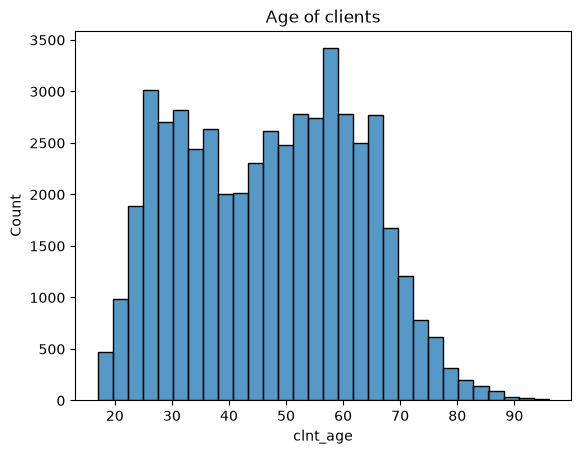

median age: 48.0


In [126]:
# ..............................................................
# STEP 9 – WHO ARE THE CLIENTS?
# ..............................................................
# 9.1 AGE

sns.histplot(clients["clnt_age"], bins=30)
plt.title("Age of clients")
plt.show()

print("median age:", clients["clnt_age"].median())

In [127]:
# 9.2 AGE GROUPS

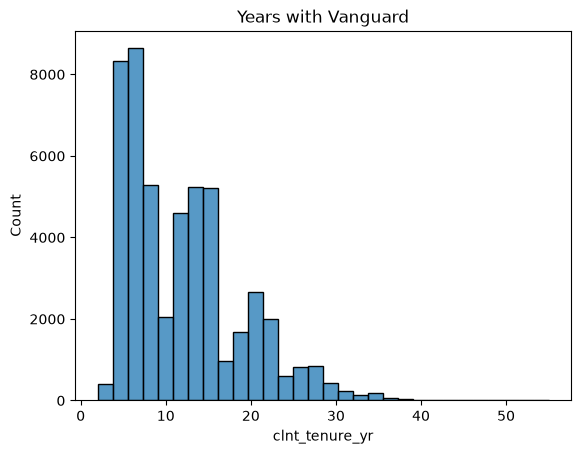

median tenure: 11.0 years
clients with less than 5 years: 7.5 %


In [128]:
# 9.3 TENURE (years with Vanguard)

sns.histplot(clients["clnt_tenure_yr"], bins=30)
plt.title("Years with Vanguard")
plt.show()

print("median tenure:", clients["clnt_tenure_yr"].median(), "years")
print(
    "clients with less than 5 years:",
    round((clients["clnt_tenure_yr"] < 5).mean() * 100, 1),
    "%",
)

# clients['clnt_tenure_yr'] < 5 checks each client and gives True if they have been with Vanguard less than 5 years, False otherwise.
# .mean() gives the share of True. Python counts True as 1 and False as 0

In [129]:
# 9.4 GENDER

clients["gendr"].value_counts(normalize=True).round(2)

gendr
U    0.34
M    0.34
F    0.32
Name: proportion, dtype: float64

In [130]:
# ANSWER
# Clients are rather OLDER: median age 48, the biggest group seems to be 50-59
# Clients are LONG-STANDING: median 11 years with Vanguard,
#   only 7.5% have less than 5 years
#  Gender is split in 3 almost equal parts (M / F / U)

In [131]:
# ..............................................................
# STEP 10 – CLIENT BEHAVIOUR
# ..............................................................
# 10.1 How many clients finished the process (reached 'confirm')?

finished = df[df["process_step"] == "confirm"]["client_id"].unique()
clients["completed"] = clients["client_id"].isin(finished)

print("clients who finished:", round(clients["completed"].mean() * 100, 1), "%")

clients who finished: 67.6 %


In [132]:
# 10.2 Who finishes the most? (by age group)

In [133]:
# 10.3 How many visits per client?

visits = df.groupby("client_id")["visit_id"].nunique()
visits.value_counts().head(30)

visit_id
1     37504
2      9450
3      2311
4       714
5       263
6       105
7        59
8        38
9        24
10       12
12        8
11        4
13        4
14        1
17        1
15        1
18        1
Name: count, dtype: int64

In [134]:
# ANSWER
# 68% of clients finished the process
# Older clients finish less: 70+ only 57% vs 69% for under 30
# Most clients (74%) did the process in only 1 visit

In [135]:
# ..............................................................
# STEP 11 – ARE TEST AND CONTROL SIMILAR?
# ..............................................................
# If both groups have the same profile, the comparison is fair
# We want to know whether the new website makes more people finish. That’s only fair if the Test and Control groups are similar.

clients.groupby("Variation")[["clnt_age", "clnt_tenure_yr", "bal"]].mean().round(1)

,clnt_age,clnt_tenure_yr,bal
Variation,,,
Control,47.5,12.1,150151.9
Test,47.2,12.0,148962.6


In [136]:
# ANSWER
# The two groups are almost the same (age 47.5 vs 47.2, tenure 12.1 vs 12.0)
# So the comparison between the old and new website is fair

In [137]:
# ..............................................................
# STEP 12 – SAVE THE CLEAN DATA
# ..............................................................
# to_csv saves the tables for Day 3 and Tableau

df.to_csv("df_clean.csv", index=False)
clients.to_csv("df_clients.csv", index=False)

## 2. KPI Analysis

### 2.1. Completion Rate

In [138]:
# ..............................................................
# VANGUARD A/B TEST – DAY 3: COMPLETION RATE KPI
# ..............................................................
# KPI = COMPLETION RATE = % of clients who reach 'confirm'
#
# Question 1: is the completion rate higher with the NEW website (Test)?
# Question 2: do some clients complete more than others? (Test vs Control each time)
#
#   - by AGE GROUP         -> do younger or older clients complete more?
#   - by ACCOUNT BALANCE   -> do clients with more money complete more?
#   - by TENURE            -> do long-standing clients complete more than new ones?
#   - by CALLS / LOGONS    -> do more active clients complete more?

In [139]:
# ..............................................................
# STEP 1 – LOAD THE CLEAN DATA FROM DAY 1 & 2
# ..............................................................
# I import df_clients.csv because it gives me the client type (age, tenure, balance account, logs, calls)

GITHUB = "https://raw.githubusercontent.com/JovZiv/vanguard-ab-test-project2/main/"

clients = pd.read_csv(
    GITHUB + "df_clients.csv"
)  # 1 row = 1 client, with 'completed' (True/False) -> did they complete all the steps (yes or no)

print(clients.shape)
clients.head(12)

(50487, 11)


,client_id,Variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,completed
0,9988021,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0,False
1,8320017,Test,22.0,274.0,34.5,M,2.0,36001.90,5.0,8.0,True
2,4033851,Control,12.0,149.0,63.5,M,2.0,142642.26,5.0,8.0,True
3,1982004,Test,6.0,80.0,44.5,U,2.0,30231.76,1.0,4.0,True
4,9294070,Control,5.0,70.0,29.0,U,2.0,34254.54,0.0,3.0,False
5,9466803,Test,11.0,137.0,27.0,F,2.0,46131.19,1.0,4.0,False
6,3170143,Test,21.0,254.0,53.5,F,2.0,192109.59,6.0,9.0,True
7,6651403,Control,13.0,162.0,56.5,M,2.0,324712.88,4.0,7.0,True
8,5887227,Test,6.0,79.0,32.5,U,2.0,60274.39,1.0,4.0,True
9,2105948,Control,6.0,74.0,61.5,U,2.0,39795.28,1.0,4.0,True


In [140]:
# ..............................................................
# STEP 1B – CREATE THE AGE GROUPS
# ..............................................................
# clnt_age is a number (ex: 47.5) -> too many different values to compare.
# pd.cut puts each client in an age box:
#   bins   = the limits of the boxes  -> 0-30, 30-40, 40-50, 50-60, 60-70, 70-100
#   labels = the name of each box
# (right=False means 30 goes in '30-39', not in '<30')

clients["age_group"] = pd.cut(
    clients["clnt_age"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"],
    right=False,
)

# check: how many clients in each age group?
clients["age_group"].value_counts().sort_index()

age_group
<30       8531
30-39     9673
40-49     8667
50-59    11058
60-69     9127
70+       3431
Name: count, dtype: int64

In [141]:
# ..............................................................
# STEP 1C – CHECK THE DISTRIBUTION OF THE WHOLE CLEAN DATASET
# ..............................................................
# Before looking at completion, we look at EVERY column of the clean data:
# what do Vanguard's clients look like, and is the data NORMAL?
#
# A NORMAL distribution = a symmetric 'bell curve':
#   - we wantmost clients to be in the middle, fewer and fewer on each side
#   - the MEAN and the MEDIAN are (almost) the same
#
# Why check it?
#   - it tells us if the MEAN is a good summary (yes if normal, no if very skewed)
#   - some hypothesis tests (Day 4) assume normal data
#
# Our columns:
#   NUMBERS    -> age, tenure (years and months), number of accounts, balance,
#                 calls and logons in the last 6 months
#   CATEGORIES -> gender, Variation (Test / Control)
#
# 3 tools for the numbers:
#   1. a HISTOGRAM with the mean (red) and the median (black)  -> look at the shape
#   2. the SKEWNESS = how much the curve leans to one side
#        about 0      -> symmetric
#        > 1 or < -1  -> strongly skewed (long tail on one side)
#   3. a NORMALITY TEST: p-value < 0.05 -> NOT normal (for day 4)

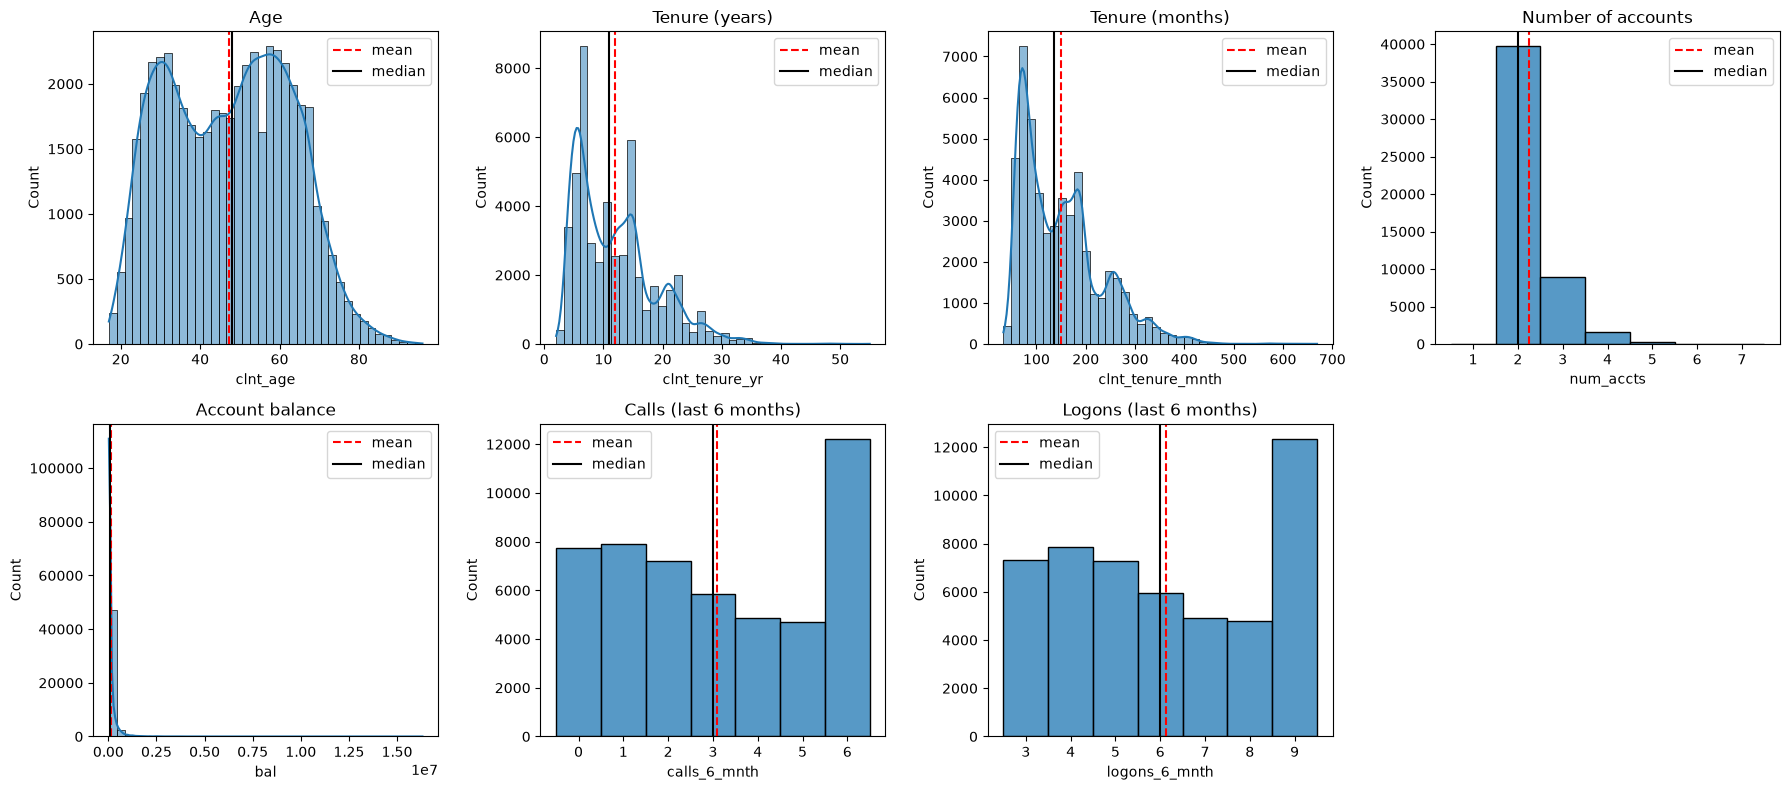

In [142]:
numeric_columns = {
    "clnt_age": "Age",
    "clnt_tenure_yr": "Tenure (years)",
    "clnt_tenure_mnth": "Tenure (months)",
    "num_accts": "Number of accounts",
    "bal": "Account balance",
    "calls_6_mnth": "Calls (last 6 months)",
    "logons_6_mnth": "Logons (last 6 months)",
}

# one histogram per column (2 rows x 4 columns of charts)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

# number of accounts, calls and logons only take whole numbers (1, 2, 3...)
# -> one bar per value (discrete=True), no smooth curve
whole_numbers = ["num_accts", "calls_6_mnth", "logons_6_mnth"]

for ax, (col, name) in zip(axes, numeric_columns.items()):
    if col in whole_numbers:
        sns.histplot(clients[col], discrete=True, ax=ax)
    else:
        sns.histplot(clients[col], bins=40, kde=True, ax=ax)
    ax.axvline(clients[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(clients[col].median(), color="black", linestyle="-", label="median")
    ax.set_title(name)
    ax.legend()
axes[-1].axis("off")  # the 8th box is empty
plt.tight_layout()
plt.show()

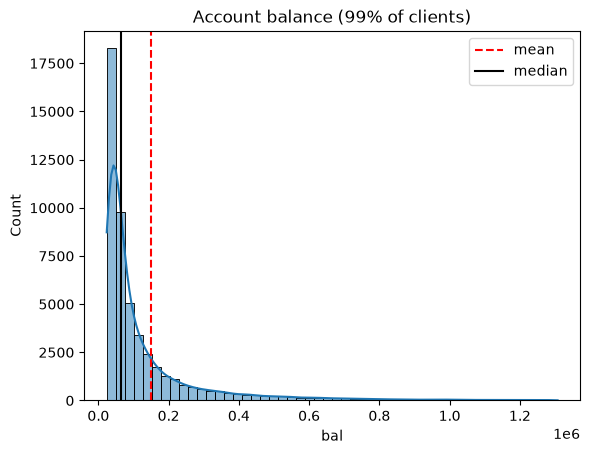

In [143]:
# Balance: a few clients have millions, so the chart above is squeezed on the left.
# We zoom on 99% of the clients (we hide the 1% richest) to see the shape better.
limit = clients["bal"].quantile(0.99)
sns.histplot(clients.loc[clients["bal"] < limit, "bal"], bins=50, kde=True)
plt.axvline(clients["bal"].mean(), color="red", linestyle="--", label="mean")
plt.axvline(clients["bal"].median(), color="black", linestyle="-", label="median")
plt.title("Account balance (99% of clients)")
plt.legend()
plt.show()


# Also the numbers aren’t really decimals they are 1e6 so to have the correct balance you multiply by 1,000,000

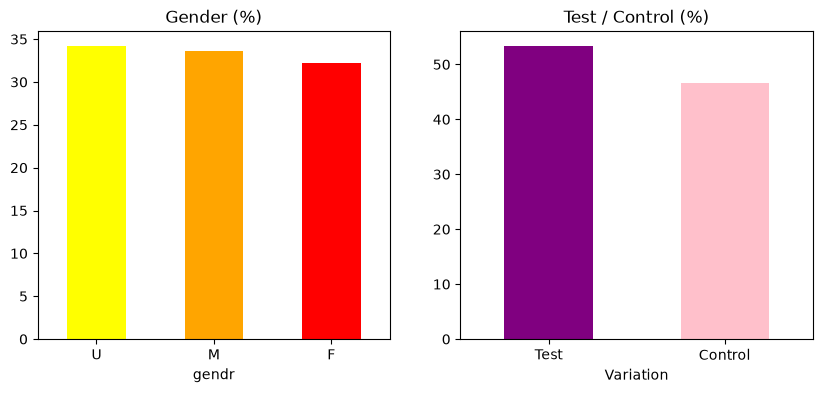

gendr
U    34.2
M    33.6
F    32.2
Name: proportion, dtype: float64
Variation
Test       53.4
Control    46.6
Name: proportion, dtype: float64


In [144]:
# Category columns: we count how many clients are in each category
# .mul is used to have the percentage
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

clients["gendr"].value_counts(normalize=True).mul(100).plot(
    kind="bar", ax=axes[0], color=["yellow", "orange", "red"]
)
axes[0].set_title("Gender (%)")
axes[0].tick_params(axis="x", rotation=0)

clients["Variation"].value_counts(normalize=True).mul(100).plot(
    kind="bar", ax=axes[1], color=["purple", "pink"]
)
axes[1].set_title("Test / Control (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.show()

# NB: Variation (Test / Control)

print(clients["gendr"].value_counts(normalize=True).mul(100).round(1))
print(clients["Variation"].value_counts(normalize=True).mul(100).round(1))

In [145]:
# INTERPRETATION – DISTRIBUTION OF THE CLEAN DATASET (50,487 clients)
#
# None of the number columns is normal (all p-values < 0.05).
# Careful: with 50,000 clients the test rejects even small differences,
# so we always look at the charts too - here the charts confirm it.
#
# AGE -> symmetric, but NOT a bell curve: it has TWO peaks
#   - mean 47.3 and median 48.0 are almost the same, skewness 0.08
#   - 2 peaks: around 30 and around 55-60 -> 2 main types of clients:
#     young adults and people close to retirement (min 17, max 96)
#
# TENURE (years and months) -> skewed to the right (skewness around 1.0)
#   - mean 12.0 > median 11.0 years; most clients have been in Vanguard for 4-16 years,
#     a few have 30-55 years (long tail on the right)
#   - years and months show the SAME information (months = years x 12),
#     so we only need one of them in the analysis
#
# NUMBER OF ACCOUNTS -> skewed to the right (skewness 2.3)
#   - almost 8 clients out of 10 have exactly 2 accounts
#   - a few have 3 to 7, only 1 client has 1 account
#   -> very little variety: this column cannot explain much
#
# BALANCE -> very strongly skewed to the right (skewness 11.5)
#   - mean 149,517 is more than 2x the median 65,734
#   - most clients have 25,000-140,000, a few have millions (max 16 million)
#   -> the MEDIAN is a better summary than the mean
#   -> that is why we cut balance in QUARTILES (4 groups of the same size)
#
# CALLS and LOGONS (last 6 months) -> flat, with a big pile at the maximum
#   - calls go from 0 to 6, logons from 3 to 9: only 7 possible values
#   - about 1 client in 4 is exactly at the maximum (6 calls / 9 logons) => a bit confusing for me, I am not sure there is a relationship there.
#
#  It can mean that the data was probably CAPPED: '6' may mean '6 or more'?
#
#
# GENDER -> 3 almost equal groups: U 34.2 %, M 33.6 %, F 32.2 % => Yeah we don't have to analyse gender, probably no effect of completion :D
#
# TEST / CONTROL -> Test 53.4 %, Control 46.6 %
#   - not exactly 50/50, but both groups are very large (27,000 vs 23,500)
#   - Day 2 showed they have the same profile (age, tenure, balance) -> so that is a fair comparison
#
# CONCLUSION: the clean data is NOT normal. This does not block the analysis:
#   - we describe skewed columns with the MEDIAN, not the mean
#   - we choose groups that fit each distribution (equal ranges for age, quartiles for balance)
#   - for our KPI (completed: yes / no) we need a test that does not need normal data (I think?)

           Did not finish (%)  Finished (%)
Variation                                  
Control                  34.4          65.6
Test                     30.7          69.3


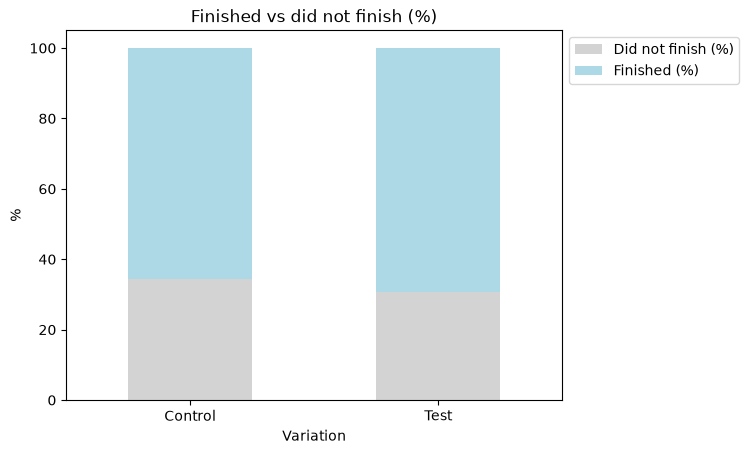

In [146]:
# ..............................................................
# STEP 1D – DISTRIBUTION OF THE COMPLETION RATE (our KPI)
# ..............................................................
# Now we look at our KPI: 'completed' (True = the client reached 'confirm')
#
# 1. 'completed' only has 2 values (True / False = 1 / 0)
#    -> it can NEVER be a bell curve: it is a yes/no variable (Bernoulli)

# Variation is (Test / Control)

completed_split = (
    pd.crosstab(clients["Variation"], clients["completed"], normalize="index") * 100
)
completed_split.columns = ["Did not finish (%)", "Finished (%)"]
print(completed_split.round(1))

completed_split.plot(kind="bar", stacked=True, color=["lightgrey", "lightblue"])
plt.title("Finished vs did not finish (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

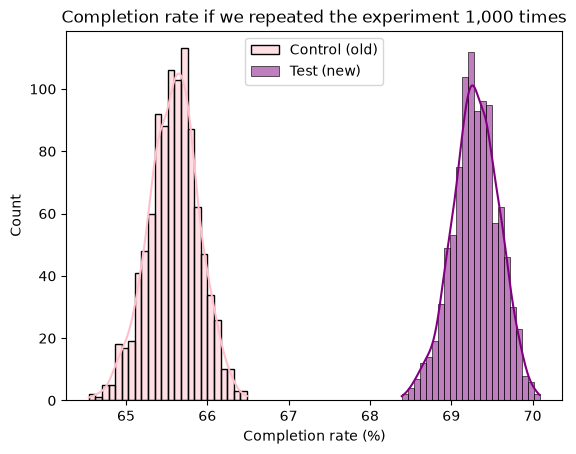

Control: from 64.5 to 66.5 %
Test   : from 68.4 to 70.1 %


In [147]:
# 2. But the COMPLETION RATE (a %) behaves differently.
#    If we repeated the experiment many times, the rate would change a little each time.
#    We can SIMULATE this: we draw clients at random (with replacement) 1,000 times or more ?
#    and compute the completion rate each time (this is called BOOTSTRAP).

rates = {"Control": [], "Test": []}
for group in ["Control", "Test"]:
    group_completed = clients.loc[
        clients["Variation"] == group, "completed"
    ]  # Variation (Test / Control)
    for i in range(1000):
        sample = group_completed.sample(frac=1, replace=True)  # same size, random draw
        rates[group].append(sample.mean() * 100)

rates = pd.DataFrame(rates)

sns.histplot(rates["Control"], color="pink", kde=True, label="Control (old)")
sns.histplot(rates["Test"], color="purple", kde=True, label="Test (new)")
plt.title("Completion rate if we repeated the experiment 1,000 times")
plt.xlabel("Completion rate (%)")
plt.legend()
plt.show()

print(
    "Control: from",
    rates["Control"].min().round(1),
    "to",
    rates["Control"].max().round(1),
    "%",
)
print(
    "Test   : from",
    rates["Test"].min().round(1),
    "to",
    rates["Test"].max().round(1),
    "%",
)

In [148]:
# INTERPRETATION – DISTRIBUTION OF THE COMPLETION RATE
#
# 1. 'completed' is a YES / NO variable -> it is not normal (only 2 values)
#    Control: 65.6 % finished, 34.4 % did not
#    Test   : 69.3 % finished, 30.7 % did not
#
# 2. But the COMPLETION RATE itself follows a NORMAL distribution (bell curve)
#    when we repeat the experiment: this is the Central Limit Theorem.
#    It works because our groups are very large (23,500 and 27,000 clients).
#
# 3. The two bell curves do NOT overlap at all:
#    - Control always stays between 64.5 % and 66.5 %
#    - Test always stays between 68.5 % and 70.1 %
#
#
# WHY IT MATTERS FOR DAY 4:
#    the proportion test (z-test) we will use relies on exactly this:
#    the completion RATE is normal even though 'completed' (yes/no) is not.
#    The non-normal data we have in STEP 1C should not block our test later.

In [149]:
# ..............................................................
# STEP 2 – A SMALL FUNCTION WE WILL REUSE FOR EVERY GROUP
# ..............................................................
# Instead of copying the same code 3 times, we write it once.
# completion_by(column) compares in 2 directions:
#
#   1. TEST vs CONTROL inside each client group
#      -> column 'Difference' = Test - Control (in points)
#
#   2. EACH CLIENT GROUP vs THE AVERAGE of its Test / Control group
#      -> columns 'Control vs avg' and 'Test vs avg' (in points)
#      -> on the chart: dashed lines = average of all Control / all Test clients
#      ex: +3 = this group completes 3 points MORE than the average of its group
#
#   3. the same Test vs Control gain, but as a RELATIVE change in %
#      -> column 'Change (%)' = Difference / Control x 100
#      (see STEP 3B: 'points' is not the same as '%')


def completion_by(column, title):
    # completion rate of each client group, for Control and Test
    table = (
        clients.pivot_table(
            index=column,
            columns="Variation",
            values="completed",
            aggfunc="mean",
            observed=True,
        )
        * 100
    )

    # average completion rate of ALL Control clients and ALL Test clients
    average = clients.groupby("Variation")["completed"].mean() * 100

    # 1. Test vs Control
    table["Difference"] = table["Test"] - table["Control"]  # in POINTS
    table["Change (%)"] = table["Difference"] / table["Control"] * 100  # in %
    # 2. each client group vs the average of its group
    table["Control vs avg"] = table["Control"] - average["Control"]
    table["Test vs avg"] = table["Test"] - average["Test"]
    print(table.round(1))

    # chart: bars = each client group, dashed lines = averages
    table[["Control", "Test"]].plot(kind="bar", color=["pink", "purple"])
    plt.axhline(
        average["Control"], color="pink", linestyle="--", label="Control average"
    )
    plt.axhline(average["Test"], color="purple", linestyle="--", label="Test average")
    plt.title("Completion rate (%) by " + title)
    plt.ylabel("% of clients who finished")
    plt.xlabel(title)
    plt.xticks(rotation=0)
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # legend outside the chart
    plt.show()
    return table

Variation
Control    65.6
Test       69.3
Name: completed, dtype: float64
Difference (Test - Control): 3.7 points
Relative change            : 5.7 %


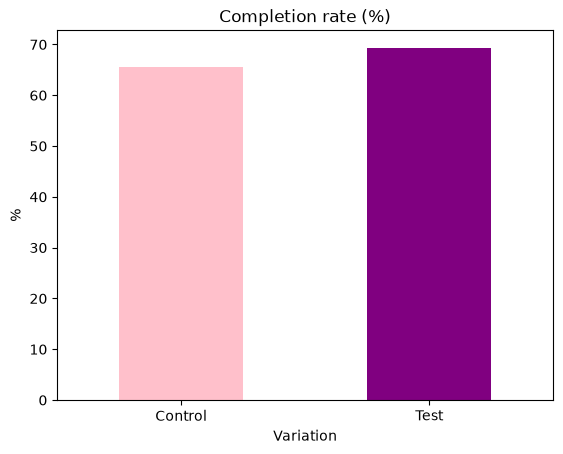

In [150]:
# ..............................................................
# STEP 3 – KPI 1: COMPLETION RATE (OVERALL)
# ..............................................................
# 'completed' was created on Day 2 (True if the client reached 'confirm')
# .mean() on True/False = share of True -> x100 to get a percentage

completion = clients.groupby("Variation")["completed"].mean() * 100
print(completion.round(1))
difference_points = completion["Test"] - completion["Control"]
change_percent = difference_points / completion["Control"] * 100
print("Difference (Test - Control):", round(difference_points, 1), "points")
print("Relative change            :", round(change_percent, 1), "%")

completion.plot(kind="bar", color=["pink", "purple"])
plt.title("Completion rate (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

In [151]:
# INTERPRETATION
# Control (old website): 65.6 %  |  Test (new website): 69.3 %
# -> the new website is better by +3.7 POINTS
# -> this is a +5.7 % RELATIVE increase (3.7 / 65.6 = about 5.7 %)
#    in words: for every 100 clients who finished on the old website,
#    about 106 finish on the new one
#
# Vanguard's threshold is 5 % -> the answer depends on how we read it (see STEP 3B):
#   - +5 POINTS needed     -> +3.7 points is BELOW the threshold
#   - +5 % RELATIVE needed -> +5.7 % is ABOVE the threshold
# (we check it properly with a hypothesis test on Day 4)

In [152]:
# ..............................................................
# STEP 3B – 'POINTS' IS NOT THE SAME AS '%'
# ..............................................................
# The completion rate is ALREADY a percentage (65.6 %, 69.3 %).
# So there are 2 ways to describe the difference between two percentages:
#
# 1. PERCENTAGE POINTS = simple subtraction
#       69.3 % - 65.6 % = +3.7 points
#  'the share of clients who finish went UP BY 3.7 points'
#
# 2. RELATIVE CHANGE (%) = the difference compared to the starting value
#       3.7 / 65.6 x 100 = about +5.7 %
#       (Python uses the exact rates 69.29 - 65.58, so it shows 5.7)
#    -> 'the completion rate grew BY 5.7 % compared to the old website'
#
# Both are correct, they just answer different questions.
# Saying '+3.7 %' would be WRONG: it mixes the two (which I did :/).
#
# Simple example to remember: a rate goes from 10 % to 15 %
#   -> +5 points  (15 - 10)
#   -> +50 %      (5 / 10): the rate is 1.5 times bigger
#
# In this notebook:
#   'Difference' column = POINTS
#   'Change (%)' column = RELATIVE change in %

overview = pd.DataFrame(
    {
        "Control (old)": [round(completion["Control"], 1)],
        "Test (new)": [round(completion["Test"], 1)],
        "Difference (points)": [round(difference_points, 1)],
        "Change (%)": [round(change_percent, 1)],
    },
    index=["Completion rate"],
)
overview

,Control (old),Test (new),Difference (points),Change (%)
Completion rate,65.6,69.3,3.7,5.7


Variation  Control  Test  Difference  Change (%)  Control vs avg  Test vs avg
age_group                                                                    
<30           67.6  74.4         6.8        10.0             2.0          5.1
30-39         67.3  70.1         2.9         4.3             1.7          0.8
40-49         68.1  70.0         1.9         2.8             2.6          0.7
50-59         66.6  68.6         2.0         3.0             1.0         -0.7
60-69         63.6  68.2         4.6         7.3            -2.0         -1.1
70+           51.9  57.0         5.2         9.9           -13.7        -12.2


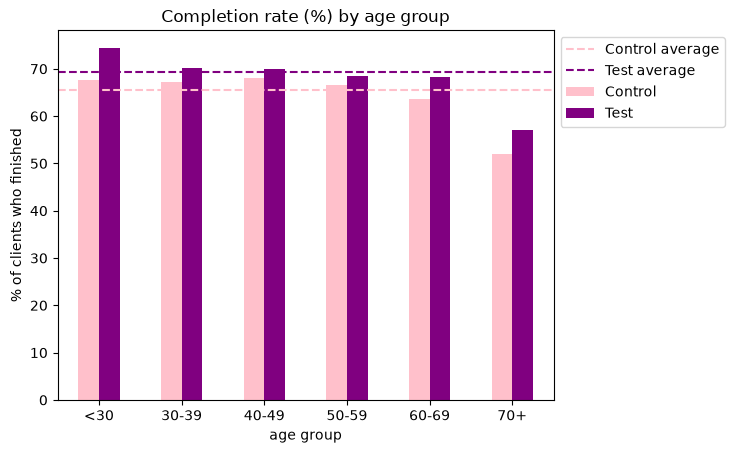

In [153]:
# ..............................................................
# STEP 4 – BY AGE GROUP
# ..............................................................
# the age groups were created in STEP 1B
by_age = completion_by("age_group", "age group")

In [154]:
# INTERPRETATION
# 1. In BOTH groups, clients under 70 complete about the same (64-74 %).
#    Clients 70+ complete much LESS: about 12-14 points below the average,
#    with the old website (51.9 %) AND the new one (57.0 %).
#
#
# 2. The new website helps EVERY age group (all differences are positive).
#    It helps most: under 30 (+6.8), 70+ (+5.2) and 60-69 (+4.6).
#    It helps least: 40-49 (+1.9) and 50-59 (+2.0).
#
# 3. Yes, older clients benefit (+5 points), but 70+ clients are still the group
#    that completes the least -> the new design does not close the gap.
#

Variation      Control  Test  Difference  Change (%)  Control vs avg  \
balance_group                                                          
Low               65.6  69.5         3.9         5.9             0.1   
Medium            65.2  68.8         3.6         5.5            -0.4   
High              64.8  68.7         3.8         5.9            -0.7   
Very high         66.6  70.2         3.6         5.4             1.1   

Variation      Test vs avg  
balance_group               
Low                    0.2  
Medium                -0.5  
High                  -0.6  
Very high              0.9  


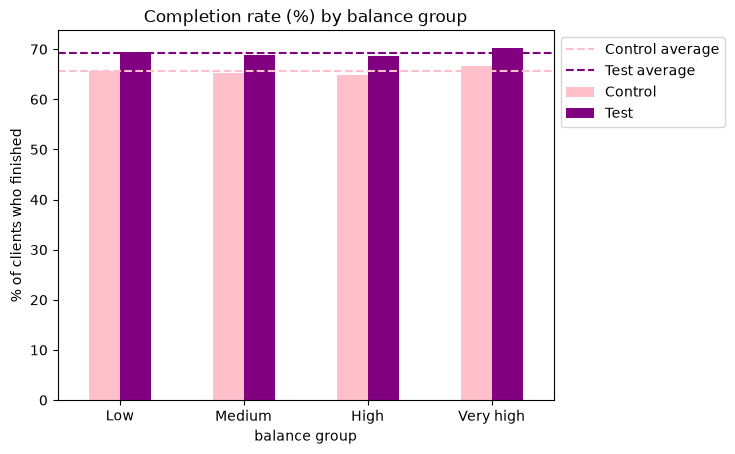

In [155]:
# ..............................................................
# STEP 5 – BY ACCOUNT BALANCE
# ..............................................................
# Balance is very uneven (a few clients have millions), so we use pd.qcut:
# it cuts the clients into 4 groups of the SAME SIZE (quartiles)
clients["balance_group"] = pd.qcut(
    clients["bal"], q=4, labels=["Low", "Medium", "High", "Very high"]
)

by_balance = completion_by("balance_group", "balance group")

In [156]:
# Check the 4 balance groups: range of each group + number of clients
balance_ranges = clients.groupby("balance_group", observed=True)["bal"].agg(
    ["min", "max", "count"]
)
balance_ranges.columns = ["Min balance", "Max balance", "Number of clients"]
balance_ranges.round(0)

,Min balance,Max balance,Number of clients
balance_group,,,
Low,23789.0,39875.0,12622
Medium,39880.0,65734.0,12622
High,65737.0,139955.0,12621
Very high,139962.0,16320040.0,12622


In [157]:
# INTERPRETATION
# 1. It looks that in both groups, all balance groups complete almost the same
#    (less than 1 point from the average). Money does not change completion.
#    So the amount of monney in bank accounts does not influence the completation of the steps for old and new website.
#
# 2. Every balance group gains about +3.6 to +3.9 points with the new website,
#    so high-balance clients benefit as much as the others.

# NB: Points = new − old
#     % = (new − old) ÷ old × 100

Variation     Control  Test  Difference  Change (%)  Control vs avg  \
tenure_group                                                          
<5 yrs           66.2  70.3         4.1         6.2             0.6   
5-9 yrs          66.2  70.1         3.9         5.9             0.6   
10-19 yrs        64.7  68.0         3.3         5.1            -0.9   
20+ yrs          65.9  69.7         3.9         5.9             0.3   

Variation     Test vs avg  
tenure_group               
<5 yrs                1.0  
5-9 yrs               0.8  
10-19 yrs            -1.3  
20+ yrs               0.4  


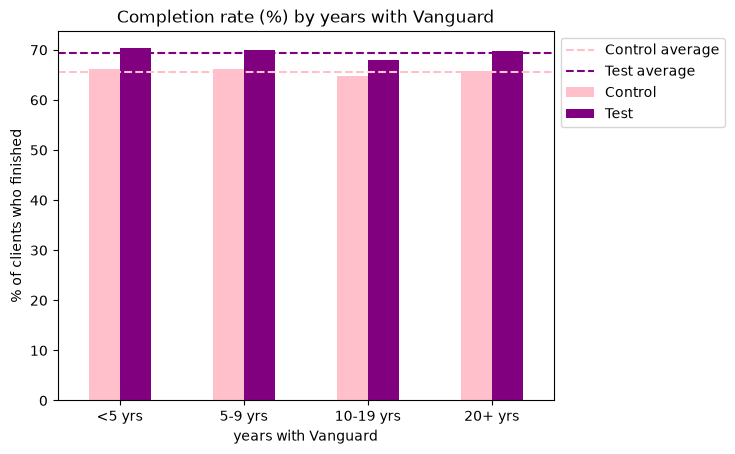

In [158]:
# ..............................................................
# STEP 6 – BY TENURE (years with Vanguard)
# ..............................................................
# here again we use pd.cut to divide the sample equally (e.g: less than five years, five to ten years...)

clients["tenure_group"] = pd.cut(
    clients["clnt_tenure_yr"],
    bins=[0, 5, 10, 20, 100],
    labels=["<5 yrs", "5-9 yrs", "10-19 yrs", "20+ yrs"],
)

by_tenure = completion_by("tenure_group", "years with Vanguard")

In [159]:
# INTERPRETATION
# 1. No: in both groups, new and long-standing clients complete almost the same
#    (about 1 point from the average). Clients with 10-19 years complete slightly less.
# 2. Yes, they react the same way: every tenure group gains +3.3 to +4.1 points.
#    Long-standing clients are NOT put off by the change.

# NB: A negative number means “this group is below the average”.
# Also The average is simply: number of clients who finished ÷ total number of clients × 100. It’s calculated separately for each website.

Variation     Control  Test  Difference  Change (%)  Control vs avg  \
calls_6_mnth                                                          
0                62.8  65.5         2.7         4.3            -2.8   
1                64.9  68.4         3.5         5.3            -0.7   
2                64.5  69.6         5.2         8.0            -1.1   
3                67.7  69.6         1.9         2.8             2.2   
4                65.1  69.2         4.1         6.2            -0.4   
5                66.1  70.7         4.6         7.0             0.5   
6                67.3  71.6         4.2         6.3             1.8   

Variation     Test vs avg  
calls_6_mnth               
0                    -3.8  
1                    -0.9  
2                     0.3  
3                     0.4  
4                    -0.1  
5                     1.4  
6                     2.3  


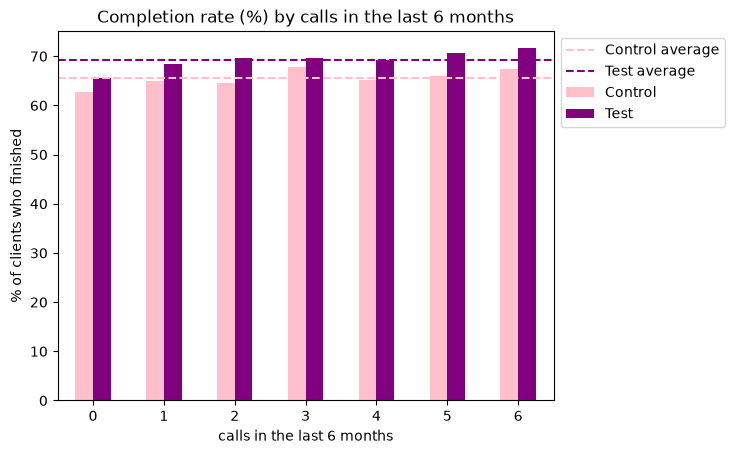

In [160]:
# ..............................................................
# STEP 6B – BY NUMBER OF CALLS (last 6 months)
# ..............................................................
# Calls = how many times the client phoned Vanguard in the last 6 months (0 to 6)
# A client who calls a lot may need more help -> does the new website help them?
# There are only 7 values, so we keep each value as its own group.

clients["calls_6_mnth"] = clients["calls_6_mnth"].astype(int)  # 6.0 -> 6 (nicer labels)
by_calls = completion_by("calls_6_mnth", "calls in the last 6 months")

In [161]:
# INTERPRETATION
# 1. In BOTH groups, clients who call MORE complete a tiny bit MORE:
#    - 0 calls: Control 62.8 %  Test 65.5 % (the lowest, ~3-4 points below average)
#    - 6 calls: Control 67.3 %  Test 71.6 % (the highest, ~2 points above average)
#    -> clients who are in contact with Vanguard are more engaged
# 2. The new website helps at EVERY level of calls (+1.9 to +5.2 points)
#    - biggest gains: 2 calls (+5.2), 5 calls (+4.6), 6 calls (+4.2)
#    - smallest gain: 3 calls (+1.9)

Variation      Control  Test  Difference  Change (%)  Control vs avg  \
logons_6_mnth                                                          
3                 62.8  65.9         3.2         5.0            -2.8   
4                 65.2  68.3         3.1         4.8            -0.4   
5                 64.3  69.3         5.1         7.9            -1.3   
6                 67.9  69.6         1.7         2.5             2.3   
7                 65.1  69.0         3.9         6.0            -0.5   
8                 65.6  70.2         4.6         7.1             0.0   
9                 67.3  71.6         4.3         6.4             1.7   

Variation      Test vs avg  
logons_6_mnth               
3                     -3.4  
4                     -1.0  
5                      0.0  
6                      0.3  
7                     -0.3  
8                      0.9  
9                      2.3  


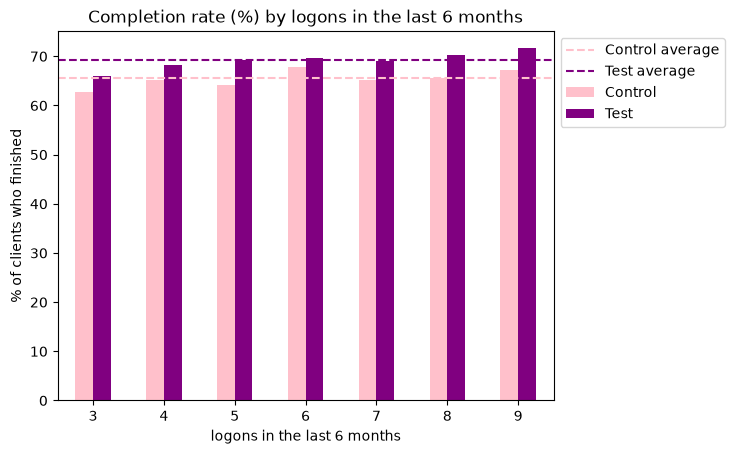

In [162]:
# ..............................................................
# STEP 6C – BY NUMBER OF LOGONS (last 6 months)
# ..............................................................
# Logons = how many times the client logged on to the website in the last 6 months (3 to 9)
# Do clients who use the website often find the new design easier?

clients["logons_6_mnth"] = clients["logons_6_mnth"].astype(
    int
)  # 9.0 -> 9 (nicer labels)
by_logons = completion_by("logons_6_mnth", "logons in the last 6 months")


# NB: A negative number means “this group is below the average”.

In [163]:
# Calls and logons look very similar -> are they linked?
# crosstab = count the clients for each pair (calls, logons)
pd.crosstab(clients["calls_6_mnth"], clients["logons_6_mnth"])

logons_6_mnth,3,4,5,6,7,8,9
calls_6_mnth,,,,,,,
0,7311,347,53,10,6,4,1
1,0,7508,339,48,9,2,2
2,0,0,6891,279,34,9,2
3,0,0,0,5628,199,24,2
4,0,0,0,0,4665,164,18
5,0,0,0,0,0,4607,100
6,0,0,0,0,0,0,12225


In [164]:
# INTERPRETATION
# 1. Same pattern as calls: clients who log on MORE complete slightly MORE
#    - 3 logons: Control 62.8 % and Test 65.9 % (the lowest)
#    - 9 logons: Control 67.3 % and Test 71.6 % (the highest)
# 2. The new website helps at EVERY level of logons (+1.7 to +5.1 points)
#
# 3. IMPORTANT: calls and logons are almost the SAME information
#    - the table shows that almost every client has logons = calls + 3
#      (0 calls -> 3 logons, 1 call -> 4 logons, ..., 6 calls -> 9 logons)
#    -> the two columns are very strongly linked, so they tell the same story:
#       ACTIVE clients complete a bit more, and the new website helps all of them
#
#  I think in the presentation, we can show only ONE of them otherwise it does not make sens (ex: logons)

Variation  Control  Test  Difference  Change (%)  Control vs avg  Test vs avg
gendr                                                                        
F             63.4  66.9         3.5         5.5            -2.2         -2.4
M             66.5  70.7         4.3         6.4             0.9          1.4
U             66.8  70.2         3.4         5.1             1.2          0.9


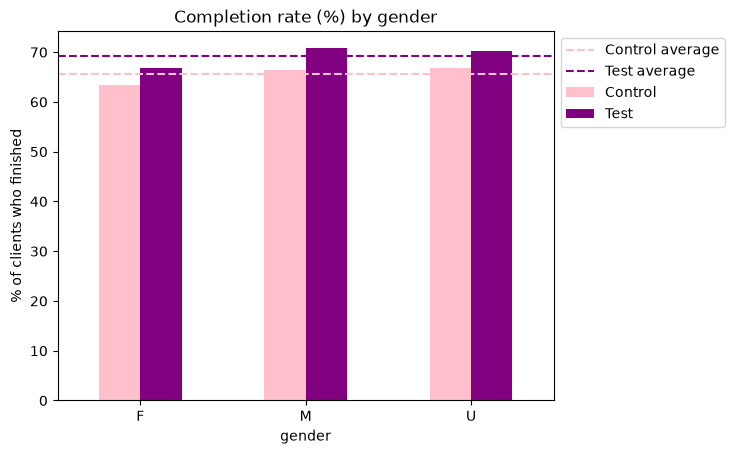

In [165]:
# ..............................................................
# STEP 6D – BY GENDER
# ..............................................................
# Gender has 3 groups: F (female), M (male), U (unknown / not given)
# Do men and women complete the same? Does the new website help them the same way?

by_gender = completion_by("gendr", "gender")

In [166]:
# INTERPRETATION
# 1. Women complete slightly LESS than the others, with both websites:
#    - F: Control 63.4 % and Test 66.9 %  (about 2 points below the average)
#    - M: Control 66.5 % and Test 70.7 %
#    - U: Control 66.8 % and Test 70.2 %
# 2. The new website helps all 3 groups: +3.4 to +4.3 points (+5.1 to +6.5 %)
# 3. The differences are small compared to age (70+ is 12-14 points below average)
#    -> gender has only a small effect on completion

In [167]:
# ..............................................................
# STEP 7 – SUMMARY: WHO GAINS THE MOST WITH THE NEW WEBSITE?
# ..............................................................
# We put all the groups together in one table, with:
#   - the gain in POINTS   (Test - Control)
#   - the gain in %        (POINTS / Control x 100)
tables = {
    "Age": by_age,
    "Balance": by_balance,
    "Tenure": by_tenure,
    "Calls": by_calls,
    "Logons": by_logons,
    "Gender": by_gender,
}

summary = pd.concat(
    {
        name: t[["Control", "Test", "Difference", "Change (%)"]]
        for name, t in tables.items()
    }
).round(1)

summary = summary.reset_index()
summary.columns = [
    "Category",
    "Group",
    "Control (%)",
    "Test (%)",
    "Gain (points)",
    "Gain (%)",
]
summary.sort_values("Gain (points)", ascending=False)

,Category,Group,Control (%),Test (%),Gain (points),Gain (%)
0,Age,<30,67.6,74.4,6.8,10.0
5,Age,70+,51.9,57.0,5.2,9.9
16,Calls,2,64.5,69.6,5.2,8.0
23,Logons,5,64.3,69.3,5.1,7.9
26,Logons,8,65.6,70.2,4.6,7.1
19,Calls,5,66.1,70.7,4.6,7.0
4,Age,60-69,63.6,68.2,4.6,7.3
29,Gender,M,66.5,70.7,4.3,6.4
27,Logons,9,67.3,71.6,4.3,6.4
20,Calls,6,67.3,71.6,4.2,6.3


In [168]:
# INTERPRETATION – WHO GAINS THE MOST?
# Gain (points) = Test % - Control %         ex: 74.4 - 67.6 = +6.8 points
# Gain (%)      = points / Control % x 100   ex: 6.8 / 67.6  = +10.0 %
#
# 1. EVERY group gains (no negative number): the new website seems to help all types of clients
#
# 2. AGE makes the biggest difference:
#    - under 30 : +6.8 points (+10.0 %)  -> the biggest gain
#    - 70+      : +5.2 points (+9.9 %)   -> big gain, but they still complete the least (57 %)
#    - 60-69    : +4.6 points (+7.3 %)
#    - 40-59    : only +1.9 to +2.0 points (+2.8 to +3.0 %) -> the smallest gains
#
# 3. BALANCE and TENURE make no difference:
#    all their groups gain about the same (+3.3 to +4.1 points, +5.1 to +6.2 %),
#    very close to the overall +3.7 points (+5.7 %)
#
# 4. CALLS and LOGONS: gains go up and down (+1.7 to +5.2 points, +2.5 to +8.0 %)
#    without a clear pattern -> activity does not change how much clients gain
#
# Note: the same number of POINTS can mean a different %:
#    +5.2 points for 70+ = +9.9 % (because they start low, at 51.9 %)
#    +4.2 points for 6 calls = +6.3 % (because they start high, at 67.3 %)

In [169]:
# ..............................................................
# VANGUARD A/B TEST – DAY 4: HYPOTHESIS TESTING
# ..............................................................
# On Day 3 we SAW a difference: Test completes 69.3 %, Control 65.6 % (+3.7 points).
# Today we ask: is this difference REAL, or could it be just CHANCE?
#
# Tool = HYPOTHESIS TEST
#   H0 (null hypothesis)        -> "there is NO difference" (the boring answer)
#   H1 (alternative hypothesis) -> "there IS a difference"  (what we want to show)
#
#   p-value = if H0 were true, how likely is it to see a difference as big as ours?
#     p < 0.05  -> very unlikely by chance -> we REJECT H0   (the difference is real)
#     p >= 0.05 -> could be chance         -> we CANNOT reject H0
#
#   alpha = 0.05 = our significance level (we accept a 5 % risk of being wrong)
#
# Test used = T-TEST (compares the MEANS of two groups)
#   - 'completed' is True/False = 1/0 -> its MEAN is the completion rate
#   - so a t-test on 'completed' compares the two completion rates
#   - Day 3 STEP 1D showed the completion RATE is normal (bell curve)
#     thanks to our big groups -> the t-test is allowed
#   - we use Welch's t-test (equal_var=False): it does not assume both groups
#     have the same variance -> safer
#
# Plan:
#   TEST 1 – Is the completion rate different between Test and Control?
#   TEST 2 – Is the increase above Vanguard's 5 % cost-effectiveness threshold?
#   TEST 3 – Other hypotheses: are the two groups similar (age, tenure, balance)?
#   TEST 4 – Completion rate by age group (Test vs Control in each group)

In [ ]:
# ..............................................................
# STEP 1 – LOAD THE CLEAN DATA
# ..............................................................

# Load the client-level completion data from your Windows project folder
FOLDER = Path(
    r"C:\Ironhack Data Analysis - Sep2026\Ironhack_Projects\Unit_5\vanguard-ab-test-project2"
)

clients = pd.read_csv(FOLDER / "df_clients.csv")
clients = clients.drop(columns=["age_group"], errors="ignore")

ALPHA = 0.05  # significance level used for every test

# 1 = finished, 0 = did not finish
control = clients.loc[clients["Variation"] == "Control", "completed"].astype(int)
test = clients.loc[clients["Variation"] == "Test", "completed"].astype(int)

print(
    "Control:",
    len(control),
    "clients, completion rate",
    round(control.mean() * 100, 2),
    "%",
)
print(
    "Test   :", len(test), "clients, completion rate", round(test.mean() * 100, 2), "%"
)

Control: 23526 clients, completion rate 65.58 %
Test   : 26961 clients, completion rate 69.29 %


In [179]:
# ..............................................................
# STEP 2 – TEST 1: IS THE COMPLETION RATE DIFFERENT?
# ..............................................................
# H0: completion rate Test = completion rate Control
# H1: completion rate Test ≠ completion rate Control   (two-sided)
#
# stats.ttest_ind(group_a, group_b) returns:
#   - t (t-statistic) = size of the difference, measured in 'standard errors'
#                       (|t| > about 2 -> usually significant)
#   - p-value

t_stat, p_value = stats.ttest_ind(test, control, equal_var=False)

difference = (test.mean() - control.mean()) * 100
print("Difference (Test - Control):", round(difference, 2), "points")
print("t-statistic:", round(t_stat, 2))
print("p-value    :", p_value)

if p_value < ALPHA:
    print(
        "-> p < 0.05: we REJECT H0. The completion rates are significantly different."
    )
else:
    print("-> p >= 0.05: we CANNOT reject H0. The difference could be chance.")

Difference (Test - Control): 3.71 points
t-statistic: 8.88
p-value    : 6.803126719143543e-19
-> p < 0.05: we REJECT H0. The completion rates are significantly different.


In [180]:
# ..............................................................
# STEP 2B – ONE-SIDED VERSION: IS TEST *HIGHER* THAN CONTROL?
# ..............................................................
# Test 1 only says 'different'. The business question is 'is the new website BETTER?'
# H0: completion rate Test <= completion rate Control
# H1: completion rate Test >  completion rate Control   (one-sided, alternative='greater')

t_stat_1s, p_value_1s = stats.ttest_ind(
    test, control, equal_var=False, alternative="greater"
)
print("t-statistic:", round(t_stat_1s, 2))
print("p-value    :", p_value_1s)

if p_value_1s < ALPHA:
    print(
        "-> We REJECT H0: the new website has a significantly HIGHER completion rate."
    )
else:
    print("-> We CANNOT reject H0.")

t-statistic: 8.88
p-value    : 3.4015633595717713e-19
-> We REJECT H0: the new website has a significantly HIGHER completion rate.


In [181]:
# ..............................................................
# STEP 2C – CONFIDENCE INTERVAL OF THE DIFFERENCE (95 %)
# ..............................................................
# The p-value says 'is there a difference?'.
# The confidence interval says 'HOW BIG is the difference, probably?'
#
#   standard error (SE) = how much the difference would move if we repeated the experiment
#   95 % CI = difference ± 1.96 x SE
#   -> if 0 is NOT inside the interval, the difference is significant

se = np.sqrt(test.var() / len(test) + control.var() / len(control))
diff = test.mean() - control.mean()
ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se

print("Difference          :", round(diff * 100, 2), "points")
print(
    "95 % CI             : from",
    round(ci_low * 100, 2),
    "to",
    round(ci_high * 100, 2),
    "points",
)

Difference          : 3.71 points
95 % CI             : from 2.89 to 4.53 points


In [182]:
# INTERPRETATION – TEST 1
# - difference = +3.71 points, t = 8.88, p-value = 6.8e-19 (TINY)
# - p is far below 0.05 -> we REJECT H0
# - the new website really increases the completion rate: it is NOT chance
# - 95 % CI: about +2.9 to +4.5 points -> 0 is not inside, and even the
#   lowest value is clearly positive

In [183]:
# ..............................................................
# STEP 3 – TEST 2: COST-EFFECTIVENESS THRESHOLD (5 %)
# ..............................................................
# Vanguard says: the new design is only worth its cost if the completion rate
# goes up by AT LEAST 5 %.
# (see Day 3 STEP 3B: '5 %' can mean 5 POINTS or a 5 % RELATIVE increase -> we test both)
#
# H0: increase <= threshold   (the new design is NOT worth it)
# H1: increase >  threshold   (the new design IS worth it)
#
# Trick to test 'Test - Control > threshold' with ttest_ind:
#   we SUBTRACT the threshold from every Test value, then test 'greater'.
#   Subtracting a number moves the mean, but does not change the spread (variance).


def threshold_test(threshold, label):
    t_s, p_v = stats.ttest_ind(
        test - threshold, control, equal_var=False, alternative="greater"
    )
    print(label)
    print("   threshold   :", round(threshold * 100, 2), "points")
    print("   observed    :", round((test.mean() - control.mean()) * 100, 2), "points")
    print("   t-statistic :", round(t_s, 2))
    print("   p-value     :", round(p_v, 4))
    if p_v < ALPHA:
        print("   -> We REJECT H0: the increase is significantly ABOVE the threshold.")
    else:
        print(
            "   -> We CANNOT reject H0: we cannot prove the increase is above the threshold."
        )
    print()
    return t_s, p_v


# version A: +5 percentage POINTS (65.6 % -> at least 70.6 %)
threshold_points = 0.05
tA, pA = threshold_test(threshold_points, "A) Threshold = +5 POINTS")

# version B: +5 % RELATIVE (65.6 % x 1.05 -> at least 68.9 %, so about +3.3 points)
threshold_relative = control.mean() * 0.05
tB, pB = threshold_test(threshold_relative, "B) Threshold = +5 % RELATIVE")

A) Threshold = +5 POINTS
   threshold   : 5.0 points
   observed    : 3.71 points
   t-statistic : -3.07
   p-value     : 0.9989
   -> We CANNOT reject H0: we cannot prove the increase is above the threshold.

B) Threshold = +5 % RELATIVE
   threshold   : 3.28 points
   observed    : 3.71 points
   t-statistic : 1.04
   p-value     : 0.149
   -> We CANNOT reject H0: we cannot prove the increase is above the threshold.



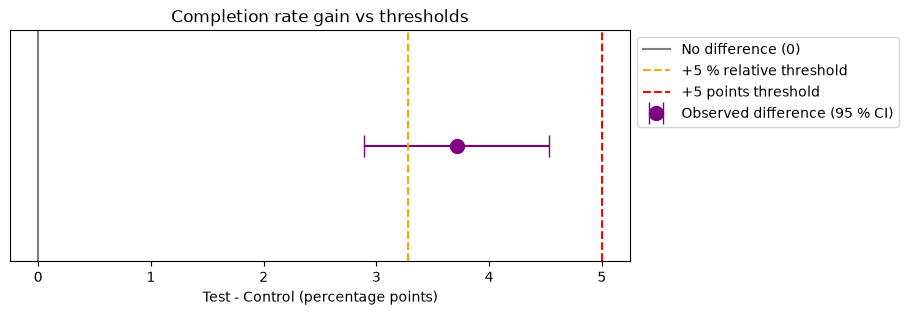

In [184]:
# Chart: the observed difference, its 95 % CI, and the thresholds
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(
    diff * 100,
    0,
    xerr=1.96 * se * 100,
    fmt="o",
    color="purple",
    capsize=8,
    markersize=10,
    label="Observed difference (95 % CI)",
)
ax.axvline(0, color="grey", linestyle="-", label="No difference (0)")
ax.axvline(
    threshold_relative * 100,
    color="orange",
    linestyle="--",
    label="+5 % relative threshold",
)
ax.axvline(
    threshold_points * 100, color="red", linestyle="--", label="+5 points threshold"
)
ax.set_yticks([])
ax.set_xlabel("Test - Control (percentage points)")
ax.set_title("Completion rate gain vs thresholds")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [185]:
# INTERPRETATION – TEST 2 (cost-effectiveness)
# A) +5 POINTS threshold:
#    - observed gain +3.7 points is BELOW 5, and the whole 95 % CI is below 5
#    - p-value = 0.999 -> we CANNOT reject H0
#    -> if Vanguard means +5 points, the new design does NOT reach the threshold
#
# B) +5 % RELATIVE threshold (= about +3.3 points):
#    - observed gain is +5.7 % relative, so it LOOKS above 5 %
#    - BUT the p-value = 0.149 (> 0.05) -> we CANNOT reject H0
#    - the 95 % CI (+2.89 to +4.53 points) still contains 3.28
#    -> we cannot be SURE the gain is above 5 %: it could be just under
#
# CONCLUSION: the new website is significantly BETTER (Test 1),
# but we cannot prove it is better ENOUGH to pass the 5 % cost threshold.
# -> recommendation: check with Vanguard which definition of '5 %' they use,
#    and/or run the experiment longer to get a more precise answer.

In [186]:
# ..............................................................
# STEP 4 – TEST 3: ARE THE TWO GROUPS SIMILAR? (other hypotheses)
# ..............................................................
# An A/B test is fair only if Test and Control clients look the same.
# If Test clients were younger, for example, the better completion could come
# from AGE and not from the new website.
#
# For each column:
# H0: mean in Test = mean in Control   (the groups are similar -> GOOD for us)
# H1: mean in Test ≠ mean in Control
#
# Note: for 'bal' (very skewed, Day 3) we also run a Mann-Whitney U test,
# which compares MEDIANS / ranks and does not care about extreme values.

columns_to_check = {
    "clnt_age": "Age",
    "clnt_tenure_yr": "Tenure (years)",
    "bal": "Account balance",
    "num_accts": "Number of accounts",
    "calls_6_mnth": "Calls (6 months)",
    "logons_6_mnth": "Logons (6 months)",
}

rows = []
for col, name in columns_to_check.items():
    a = clients.loc[clients["Variation"] == "Test", col].dropna()
    b = clients.loc[clients["Variation"] == "Control", col].dropna()
    t_s, p_v = stats.ttest_ind(a, b, equal_var=False)
    rows.append(
        {
            "Column": name,
            "Mean Control": round(b.mean(), 2),
            "Mean Test": round(a.mean(), 2),
            "t-statistic": round(t_s, 2),
            "p-value": round(p_v, 4),
            "Significant? (p < 0.05)": p_v < ALPHA,
        }
    )

balance_check = pd.DataFrame(rows)
balance_check

,Column,Mean Control,Mean Test,t-statistic,p-value,Significant? (p < 0.05)
0,Age,47.50,47.16,-2.42,0.0157,True
1,Tenure (years),12.09,11.98,-1.71,0.0865,False
2,Account balance,150151.90,148962.61,-0.44,0.6581,False
3,Number of accounts,2.26,2.25,-2.10,0.0358,True
4,Calls (6 months),3.13,3.06,-3.45,0.0006,True
5,Logons (6 months),6.17,6.10,-3.32,0.0009,True


In [187]:
# Mann-Whitney U test for balance (robust to the few clients with millions)
u_stat, p_mw = stats.mannwhitneyu(
    clients.loc[clients["Variation"] == "Test", "bal"],
    clients.loc[clients["Variation"] == "Control", "bal"],
    alternative="two-sided",
)
print(
    "Median balance Control:",
    round(clients.loc[clients["Variation"] == "Control", "bal"].median(), 0),
)
print(
    "Median balance Test   :",
    round(clients.loc[clients["Variation"] == "Test", "bal"].median(), 0),
)
print("Mann-Whitney p-value  :", round(p_mw, 4))

Median balance Control: 66031.0
Median balance Test   : 65468.0
Mann-Whitney p-value  : 0.1476


In [188]:
# INTERPRETATION – TEST 3
# - Tenure and balance: p > 0.05 -> no significant difference (balance confirmed
#   by Mann-Whitney, p = 0.15) -> the groups are comparable
# - Age, number of accounts, calls, logons: p < 0.05 -> 'significant'...
#   BUT the differences are TINY:
#     age 47.5 vs 47.2 years, calls 3.13 vs 3.06, logons 6.17 vs 6.10
#   With 50,000 clients, even a tiny difference becomes 'significant'.
#   Statistically significant ≠ important in practice.
# - Also: Test clients are slightly YOUNGER and call/log on slightly LESS.
#   Day 3 showed older clients complete less -> a 0.3-year age gap could explain
#   only a very small part of the +3.7 points, not the whole gain.
#
# -> The randomization worked well enough: the higher completion comes from the
#    NEW WEBSITE, not from different clients.

In [189]:
# ..............................................................
# STEP 5 – TEST 4: COMPLETION BY AGE GROUP (Test vs Control in each group)
# ..............................................................
# Day 3: the gain looked biggest for <30 (+6.8 pts) and 70+ (+5.2 pts),
# and smallest for 40-59 (+2 pts). Are these gains significant?
#
# For each age group:
# H0: completion Test = completion Control
# H1: completion Test ≠ completion Control

clients["age_group"] = pd.cut(
    clients["clnt_age"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"],
    right=False,
)


def test_by_group(column):
    rows = []
    for group, data in clients.groupby(column, observed=True):
        a = data.loc[data["Variation"] == "Test", "completed"].astype(int)
        b = data.loc[data["Variation"] == "Control", "completed"].astype(int)
        t_s, p_v = stats.ttest_ind(a, b, equal_var=False)
        rows.append(
            {
                "Group": group,
                "Clients": len(data),
                "Control (%)": round(b.mean() * 100, 1),
                "Test (%)": round(a.mean() * 100, 1),
                "Gain (points)": round((a.mean() - b.mean()) * 100, 1),
                "p-value": round(p_v, 4),
                "Significant? (p < 0.05)": p_v < ALPHA,
            }
        )
    return pd.DataFrame(rows)


by_age_test = test_by_group("age_group")
by_age_test

,Group,Clients,Control (%),Test (%),Gain (points),p-value,Significant? (p < 0.05)
0,<30,8531,67.6,74.4,6.8,0.0000,True
1,30-39,9673,67.3,70.1,2.9,0.0025,True
2,40-49,8667,68.1,70.0,1.9,0.0570,False
3,50-59,11058,66.6,68.6,2.0,0.0242,True
4,60-69,9127,63.6,68.2,4.6,0.0000,True
5,70+,3431,51.9,57.0,5.2,0.0025,True


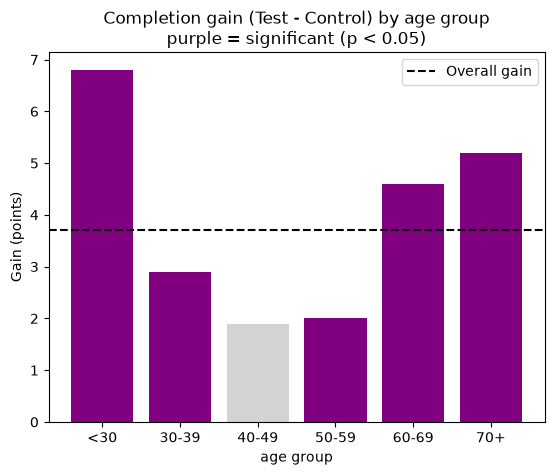

In [190]:
# Chart: gain per age group, coloured if significant
colors = [
    "purple" if s else "lightgrey" for s in by_age_test["Significant? (p < 0.05)"]
]
plt.bar(by_age_test["Group"].astype(str), by_age_test["Gain (points)"], color=colors)
plt.axhline(difference, color="black", linestyle="--", label="Overall gain")
plt.title(
    "Completion gain (Test - Control) by age group\npurple = significant (p < 0.05)"
)
plt.ylabel("Gain (points)")
plt.xlabel("age group")
plt.legend()
plt.show()

In [191]:
# INTERPRETATION – TEST 4
# - the new website helps EVERY age group (all gains are positive)
# - significant (p < 0.05) for 5 groups out of 6:
#     <30 (+6.8 pts), 60-69 (+4.6), 70+ (+5.2), 30-39 (+2.9), 50-59 (+2.0)
# - NOT significant for 40-49 (+1.9 pts, p = 0.057): the gain is small and
#   each age group has fewer clients, so the test is less precise
# - careful: testing 6 groups = 6 chances of a false positive.
#   With a stricter alpha (Bonferroni: 0.05 / 6 = 0.008):
#     still significant: <30, 30-39, 60-69, 70+
#     no longer significant: 50-59 (p = 0.024)
# -> the redesign works best for the YOUNGEST and the OLDEST clients

In [192]:
# ..............................................................
# STEP 6 – SUMMARY OF ALL TESTS
# ..............................................................
summary_tests = pd.DataFrame(
    {
        "Hypothesis (H1)": [
            "Completion rate Test ≠ Control",
            "Completion rate Test > Control",
            "Gain > +5 points threshold",
            "Gain > +5 % relative threshold",
        ],
        "Test": [
            "Welch t-test (two-sided)",
            "Welch t-test (one-sided)",
            "Welch t-test (one-sided, shifted)",
            "Welch t-test (one-sided, shifted)",
        ],
        "p-value": [p_value, p_value_1s, pA, pB],
    }
)
summary_tests["Reject H0?"] = summary_tests["p-value"] < ALPHA
summary_tests["p-value"] = summary_tests["p-value"].apply(
    lambda p: f"{p:.2e}" if p < 0.0001 else round(p, 4)
)
summary_tests

,Hypothesis (H1),Test,p-value,Reject H0?
0,Completion rate Test ≠ Control,Welch t-test (two-sided),6.80e-19,True
1,Completion rate Test > Control,Welch t-test (one-sided),3.40e-19,True
2,Gain > +5 points threshold,"Welch t-test (one-sided, shifted)",0.9989,False
3,Gain > +5 % relative threshold,"Welch t-test (one-sided, shifted)",0.149,False


In [193]:
# FINAL CONCLUSION – DAY 4
# 1. The new website INCREASES the completion rate: +3.7 points, p << 0.05.
#    This is statistically significant, not chance.
# 2. The gain does NOT significantly pass Vanguard's 5 % cost threshold:
#    - clearly below +5 points
#    - above +5 % relative on paper (+5.7 %), but not significantly (p > 0.05)
# 3. Test and Control clients have a very similar profile (differences are tiny)
#    -> the comparison is fair.
# 4. The gain is biggest for the youngest (<30) and oldest (60+) clients,
#    and not significant for 40-49.

In [197]:
# OUT = FOLDER + "tableau/"
# import os

# os.makedirs(OUT, exist_ok=True)

# clients.to_csv(OUT + "clients_tableau.csv", index=False)  # includes age_group
# by_age_test.to_csv(OUT + "age_group_tests.csv", index=False)
# balance_check.to_csv(OUT + "balance_check.csv", index=False)
# summary_tests.to_csv(OUT + "hypothesis_tests.csv", index=False)

# pd.DataFrame(
#     {
#         "metric": ["diff", "ci_low", "ci_high", "thr_points", "thr_relative"],
#         "value": [diff * 100, ci_low * 100, ci_high * 100, 5, threshold_relative * 100],
#     }
# ).to_csv(OUT + "ci_thresholds.csv", index=False)

In [198]:
# Export the completion-rate analysis datasets for Tableau
OUT = FOLDER / "tableau"
OUT.mkdir(parents=True, exist_ok=True)

clients.to_csv(OUT / "clients_tableau.csv", index=False)
by_age_test.to_csv(OUT / "age_group_tests.csv", index=False)
balance_check.to_csv(OUT / "balance_check.csv", index=False)
summary_tests.to_csv(OUT / "hypothesis_tests.csv", index=False)

pd.DataFrame({
    "metric": ["diff", "ci_low", "ci_high", "thr_points", "thr_relative"],
    "value": [
        diff * 100,
        ci_low * 100,
        ci_high * 100,
        5,
        threshold_relative * 100
    ],
}).to_csv(OUT / "ci_thresholds.csv", index=False)

print(f"Files exported successfully to: {OUT}")

Files exported successfully to: C:\Ironhack Data Analysis - Sep2026\Ironhack_Projects\Unit_5\vanguard-ab-test-project2\tableau


### 2.2. Time Spent on Each Process Step

#### Objective

The goal is to compare how much time clients spend on each step of the online process in the Test and Control groups. This helps us understand whether the new design makes the process faster or whether clients experience delays at specific steps.

#### Approach

We will use the timestamps recorded for each client's website activity to calculate the time spent on each process step, then compare the results between the two experiment groups.

In [199]:
# Check the columns and first few rows of the web activity dataset
display(df_web.head())

# Check the columns and first few rows of the experiment assignments
display(df_experiment.head())

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


**Prepare Data for Time Calculation**

Before calculating the time between process steps, we need to sort the website activity records chronologically for each client and visit. This is important because the original dataset is not necessarily ordered by timestamp.

In [200]:
# Create a copy so we don't modify the original web activity dataset
df_time = df_web.copy()

# Sort events chronologically within each client's visit
df_time = df_time.sort_values(by=["client_id", "visit_id", "date_time"])

# Display the first rows to check the chronological order
display(df_time.head(10))

,client_id,visitor_id,visit_id,process_step,date_time
285515,169,201385055_71273495308,749567106_99161211863_557568,start,2017-04-12 20:19:36
285514,169,201385055_71273495308,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
285513,169,201385055_71273495308,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
285512,169,201385055_71273495308,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
285511,169,201385055_71273495308,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
628456,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:26:55
628331,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:42:43
442857,546,475037402_89828530214,731811517_9330176838_94847,start,2017-06-17 10:03:29
442856,546,475037402_89828530214,731811517_9330176838_94847,step_1,2017-06-17 10:03:39
442855,546,475037402_89828530214,731811517_9330176838_94847,step_2,2017-06-17 10:03:52


**Calculate Time Between Process Events**

We calculate the time difference between consecutive website events for each client and visit. This gives us the elapsed time between recorded events, which we can use to investigate how long clients take to progress through the process.

Repeated steps and unusually long time intervals must be considered when interpreting the results.

In [201]:
# Group events by client and visit, then find the next event timestamp
df_time["next_date_time"] = df_time.groupby(["client_id", "visit_id"])[
    "date_time"
].shift(-1)

# Calculate the time in seconds between each event and the next one
df_time["time_seconds"] = (
    df_time["next_date_time"] - df_time["date_time"]
).dt.total_seconds()

# Display the events and their calculated time differences
display(
    df_time[
        [
            "client_id",
            "visit_id",
            "process_step",
            "date_time",
            "next_date_time",
            "time_seconds",
        ]
    ].head(10)
)

,client_id,visit_id,process_step,date_time,next_date_time,time_seconds
285515,169,749567106_99161211863_557568,start,2017-04-12 20:19:36,2017-04-12 20:19:45,9.0
285514,169,749567106_99161211863_557568,step_1,2017-04-12 20:19:45,2017-04-12 20:20:31,46.0
285513,169,749567106_99161211863_557568,step_2,2017-04-12 20:20:31,2017-04-12 20:22:05,94.0
285512,169,749567106_99161211863_557568,step_3,2017-04-12 20:22:05,2017-04-12 20:23:09,64.0
285511,169,749567106_99161211863_557568,confirm,2017-04-12 20:23:09,NaT,NaN
628456,336,649044751_80905125055_554468,start,2017-06-01 07:26:55,2017-06-01 07:42:43,948.0
628331,336,649044751_80905125055_554468,start,2017-06-01 07:42:43,NaT,NaN
442857,546,731811517_9330176838_94847,start,2017-06-17 10:03:29,2017-06-17 10:03:39,10.0
442856,546,731811517_9330176838_94847,step_1,2017-06-17 10:03:39,2017-06-17 10:03:52,13.0
442855,546,731811517_9330176838_94847,step_2,2017-06-17 10:03:52,2017-06-17 10:05:19,87.0


In [202]:
# Keep intervals that have a following event and a valid time difference
df_step_time = df_time.dropna(subset=["next_date_time", "time_seconds"]).copy()

# Check how many intervals are negative or zero
print("Zero or negative intervals:", (df_step_time["time_seconds"] <= 0).sum())

# Summarise the time intervals for each process step
step_time_summary = (
    df_step_time.groupby("process_step")["time_seconds"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(1)
)

# Display the summary statistics in seconds
display(step_time_summary)

Zero or negative intervals: 953


,count,mean,median,min,max
process_step,,,,,
confirm,13634,256.9,76.0,0.0,35680.0
start,192763,61.3,15.0,0.0,40235.0
step_1,149164,60.5,26.0,0.0,10286.0
step_2,126809,92.6,63.0,0.0,21763.0
step_3,103159,132.8,61.0,0.0,17052.0


In [203]:
# Count how many recorded intervals exceed five minutes (300 seconds)
long_intervals = df_step_time[df_step_time["time_seconds"] > 300]

print("Intervals longer than 5 minutes:", len(long_intervals))
print(
    "Percentage of all intervals:",
    round(len(long_intervals) / len(df_step_time) * 100, 2),
    "%",
)

# Check how these long intervals are distributed across process steps
display(
    long_intervals.groupby("process_step")["time_seconds"]
    .agg(["count", "median", "max"])
    .round(1)
)

Intervals longer than 5 minutes: 30316
Percentage of all intervals: 5.18 %


,count,median,max
process_step,,,
confirm,2978,964.0,35680.0
start,7365,542.0,40235.0
step_1,4830,456.0,10286.0
step_2,4679,434.0,21763.0
step_3,10464,504.5,17052.0


In [204]:
# Add each client's Test or Control assignment to the interval data
df_step_time = df_step_time.merge(
    df_experiment[["client_id", "Variation"]], on="client_id", how="inner"
)

# Check that both experiment groups are present
print(df_step_time["Variation"].value_counts())

Variation
Test       139495
Control    108293
Name: count, dtype: int64


In [205]:
# Compare elapsed time between recorded events for Test and Control
step_time_comparison = (
    df_step_time.groupby(["process_step", "Variation"])["time_seconds"]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the results for each process step and experiment group
display(step_time_comparison)

count   mean  median
process_step Variation                      
confirm      Control     1920  168.7    46.0
             Test        4089  243.7    93.0
start        Control    35737   66.8    20.0
             Test       46323   61.5    14.0
step_1       Control    26043   50.5    20.0
             Test       35527   60.7    27.0
step_2       Control    24313   92.0    64.0
             Test       29573   88.8    61.0
step_3       Control    20280  137.1    72.0
             Test       23983  129.6    58.0

In [206]:
# Identify the process step recorded immediately after each event
df_time["next_process_step"] = df_time.groupby(["client_id", "visit_id"])[
    "process_step"
].shift(-1)

# Check which events follow a confirm event within the same visit
confirm_following = df_time.loc[
    df_time["process_step"] == "confirm", "next_process_step"
].value_counts(dropna=False)

# Display the next recorded steps after confirm
display(confirm_following)

next_process_step
NaN        88872
confirm    11772
start       1109
step_1       552
step_3       194
step_2         7
Name: count, dtype: int64

In [207]:
# Keep the four main process steps for the primary time comparison
main_steps = df_step_time[
    df_step_time["process_step"].isin(["start", "step_1", "step_2", "step_3"])
].copy()

# Calculate the median elapsed time for each step and experiment group
main_step_comparison = (
    main_steps.groupby(["process_step", "Variation"])["time_seconds"].median().unstack()
)

# Calculate the difference between Test and Control in seconds
main_step_comparison["Test - Control (seconds)"] = (
    main_step_comparison["Test"] - main_step_comparison["Control"]
)

# Display the results
display(main_step_comparison)

Variation,Control,Test,Test - Control (seconds)
process_step,,,
start,20.0,14.0,-6.0
step_1,20.0,27.0,7.0
step_2,64.0,61.0,-3.0
step_3,72.0,58.0,-14.0


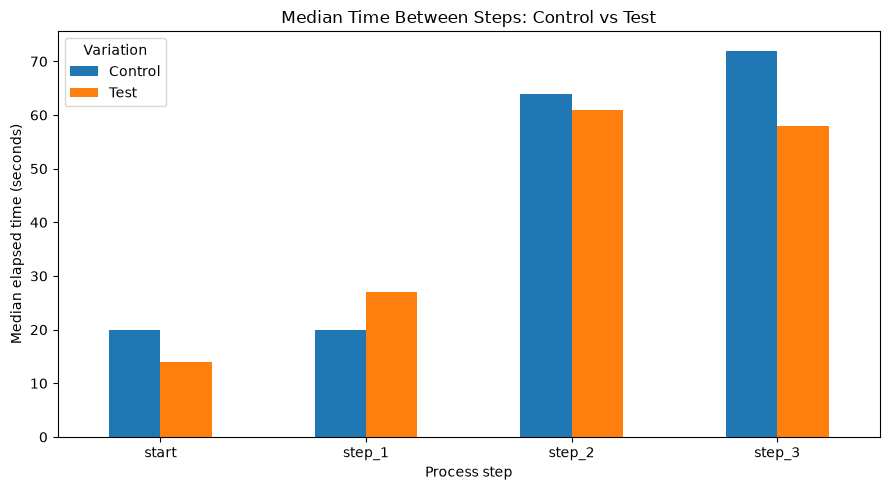

In [208]:
# Compare median elapsed time per step between Control and Test
main_step_comparison[["Control", "Test"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylabel="Median elapsed time (seconds)",
    xlabel="Process step",
    title="Median Time Between Steps: Control vs Test",
)

# Display the chart with readable labels
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Findings: Time Between Process Steps

The Test group had lower median elapsed times at three of the four main process steps.

- **Start:** The Test group had a median 6 seconds lower than Control.
- **Step 1:** The Test group had a median 7 seconds higher than Control, making this the main step to investigate further.
- **Step 2:** The Test group had a median 3 seconds lower than Control.
- **Step 3:** The Test group had a median 14 seconds lower than Control, the largest reduction among the four steps.

Overall, the results suggest that clients in the Test group progressed to their next recorded event faster at most steps, particularly `step_3`. However, `step_1` took longer in the Test group.

These values represent elapsed time between recorded events, not necessarily active time spent interacting with each step. Long pauses and repeated events may affect the measurements, so the results should be interpreted with caution. The comparison is descriptive and does not establish statistical significance or prove that the new design caused the differences.

#### Hypothesis Testing: Time per Process Step

To investigate whether the differences between the Control and Test groups are statistically significant, we compare their elapsed times for each process step.

Some clients have multiple recorded intervals at the same step. To avoid treating these intervals as independent observations, we calculate one median time per client and process step before performing the statistical tests.

In [209]:
# Keep the four process steps included in our analysis
main_steps = ["start", "step_1", "step_2", "step_3"]

# Calculate one median time per client and process step
client_step_time = (
    df_step_time[df_step_time["process_step"].isin(main_steps)]
    .groupby(["client_id", "Variation", "process_step"], as_index=False)["time_seconds"]
    .median()
)

# Check the number of clients available for each step and group
display(
    client_step_time.groupby(["process_step", "Variation"], observed=True)["client_id"]
    .count()
    .unstack()
)

Variation,Control,Test
process_step,,
start,20940,25182
step_1,19142,23168
step_2,17860,21699
step_3,16281,19986


**Hypotheses**

For each process step:

- **H0 (null hypothesis):** The Test group does not have lower elapsed times than the Control group.
- **H1 (alternative hypothesis):** The Test group has lower elapsed times than the Control group.

In [210]:
# Store the results for each process step
results = []

for step in main_steps:
    # Select the client-level times for each group
    control = client_step_time[
        (client_step_time["process_step"] == step)
        & (client_step_time["Variation"] == "Control")
    ]["time_seconds"]

    test = client_step_time[
        (client_step_time["process_step"] == step)
        & (client_step_time["Variation"] == "Test")
    ]["time_seconds"]

    # Test whether Test times are lower than Control times
    statistic, p_value = mannwhitneyu(test, control, alternative="less")

    # Save the medians and p-value
    results.append(
        {
            "process_step": step,
            "Control_median": control.median(),
            "Test_median": test.median(),
            "p_value": p_value,
        }
    )

# Create the results table
results_df = pd.DataFrame(results)

# Apply the Holm correction for multiple tests
results_df["p_value_adjusted"] = multipletests(results_df["p_value"], method="holm")[1]

# Display the results
display(results_df.round(4))

,process_step,Control_median,Test_median,p_value,p_value_adjusted
0,start,22.0,14.0,0.0,0.0
1,step_1,22.0,29.0,1.0,1.0
2,step_2,70.0,67.0,0.0,0.0
3,step_3,76.0,57.0,0.0,0.0


#### Findings: Hypothesis Testing

The results show statistically significant evidence that the Test group had lower elapsed times at `start`, `step_2` and `step_3` after correcting for multiple comparisons.

At `step_1`, the Test group had a higher median time (29 seconds compared with 22 seconds), and the test did not provide evidence that the Test group was faster.

Overall, the results suggest that the redesigned process improved the time between several steps, but `step_1` may need further investigation. These findings concern elapsed time between recorded events and do not necessarily represent active interaction time.

#### Total Process Duration

**Objective**

To compare the total time taken by clients in the Control and Test groups to complete the online process.

**Approach**

For each completed visit, we will calculate the time between the first recorded `start` event and the first subsequent `confirm` event. We will then compare the total process duration between the two experiment groups.

In [211]:
# Work with the chronologically sorted website activity data
# Keep the original dataframe unchanged
df_duration = df_time.sort_values(by=["client_id", "visit_id", "date_time"]).copy()

# Check that the timestamps are in datetime format
df_duration["date_time"] = pd.to_datetime(df_duration["date_time"])

# Display a sample of the data before calculating visit duration
display(df_duration[["client_id", "visit_id", "process_step", "date_time"]].head(10))

,client_id,visit_id,process_step,date_time
285515,169,749567106_99161211863_557568,start,2017-04-12 20:19:36
285514,169,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
285513,169,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
285512,169,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
285511,169,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
628456,336,649044751_80905125055_554468,start,2017-06-01 07:26:55
628331,336,649044751_80905125055_554468,start,2017-06-01 07:42:43
442857,546,731811517_9330176838_94847,start,2017-06-17 10:03:29
442856,546,731811517_9330176838_94847,step_1,2017-06-17 10:03:39
442855,546,731811517_9330176838_94847,step_2,2017-06-17 10:03:52


In [212]:
# Get the first recorded start time for each client visit
visit_starts = (
    df_duration[df_duration["process_step"] == "start"]
    .groupby(["client_id", "visit_id"], as_index=False)["date_time"]
    .min()
    .rename(columns={"date_time": "start_time"})
)

# Get all recorded confirmation events
visit_confirms = df_duration[df_duration["process_step"] == "confirm"][
    ["client_id", "visit_id", "date_time"]
].rename(columns={"date_time": "confirm_time"})

# Match each visit's start time with its confirmation events
completed_visits = visit_starts.merge(
    visit_confirms, on=["client_id", "visit_id"], how="inner"
)

# Keep confirmations that occurred at or after the first start
completed_visits = completed_visits[
    completed_visits["confirm_time"] >= completed_visits["start_time"]
].copy()

# Keep only the first valid confirmation for each visit
completed_visits = completed_visits.sort_values("confirm_time").drop_duplicates(
    subset=["client_id", "visit_id"], keep="first"
)

# Calculate total duration in seconds
completed_visits["duration_seconds"] = (
    completed_visits["confirm_time"] - completed_visits["start_time"]
).dt.total_seconds()

# Display a sample of completed visits
display(completed_visits.head())

,client_id,visit_id,start_time,confirm_time,duration_seconds
62109,7179755,264484508_5982901710_928530,2017-03-15 00:19:28,2017-03-15 00:26:24,416.0
83128,9584408,484298588_81471639218_981974,2017-03-15 06:03:24,2017-03-15 06:16:08,764.0
22928,2685910,607150032_7201582900_558690,2017-03-15 07:47:11,2017-03-15 07:50:33,202.0
41859,4856478,71742713_20814504119_232694,2017-03-15 07:54:41,2017-03-15 08:02:22,461.0
8540,996458,758207623_47104412307_240917,2017-03-15 09:55:00,2017-03-15 10:07:04,724.0


In [213]:
# Add the experiment assignment to each completed visit
completed_visits = completed_visits.merge(
    df_experiment[["client_id", "Variation"]], on="client_id", how="inner"
)

# Check how many completed visits belong to each group
print(completed_visits["Variation"].value_counts())

# Compare total process duration between Control and Test
duration_comparison = (
    completed_visits.groupby("Variation")["duration_seconds"]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the comparison in seconds
display(duration_comparison)

Variation
Test       17941
Control    14925
Name: count, dtype: int64


,count,mean,median
Variation,,,
Control,14925,391.1,271.0
Test,17941,374.6,237.0


#### Visualization: Median Total Process Duration

This chart compares the median total process duration for completed visits in the Control and Test groups.

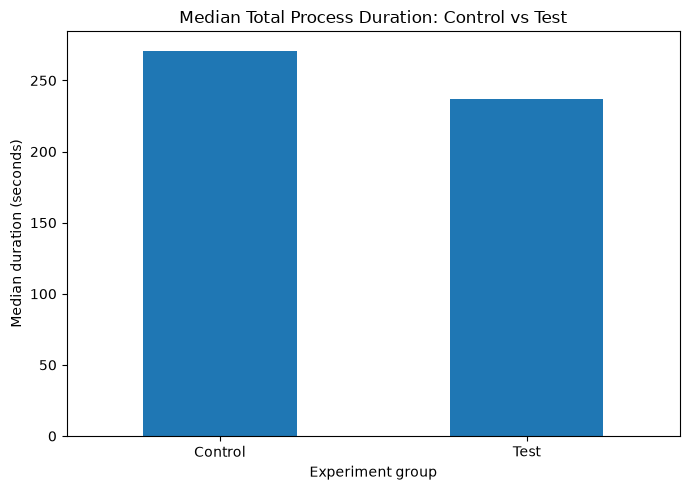

In [214]:
# Compare median total duration for completed visits
duration_comparison["median"].plot(
    kind="bar",
    figsize=(7, 5),
    ylabel="Median duration (seconds)",
    xlabel="Experiment group",
    title="Median Total Process Duration: Control vs Test",
)

# Display the chart with readable labels
plt.xticks(rotation=0)
plt.tight_layout()

#### Findings: Time-Based KPIs

The new design showed a lower median total process duration than the old design: 3 minutes and 57 seconds compared with 4 minutes and 31 seconds. This is a reduction of 34 seconds, or approximately 12.5%.

When comparing individual process steps, the new design had lower median elapsed times at `start`, `step_2` and `step_3`. However, the median time at `step_1` was 7 seconds higher than in the old design, suggesting that this step may need further investigation.

Overall, the descriptive results suggest that clients who completed the process using the new design generally did so faster. However, these results alone do not establish statistical significance or prove that the redesign caused the improvement. Total process duration was calculated only for completed visits, and the measured time represents elapsed time rather than active interaction time.

### 2.2.1 Hypothesis Test: Time at `step_1` by Age Group

**Objective**

To investigate whether the time between `step_1` and the next recorded event differs across age groups.

**Approach**

We will identify the age information available in the demographic dataset, combine it with our time-based data, and compare the time intervals across age groups. We will then perform a statistical hypothesis test to determine whether the differences are statistically significant.

**Calculate Time After `step_1`**

We will sort website events by client, visit, and timestamp. Then, we will calculate the time between each event and the next recorded event. This allows us to isolate the time intervals following `step_1`.

In [215]:
# Calculate valid elapsed times after step_1

# Sort events chronologically within each client visit
df_age_time = df.sort_values(by=["client_id", "visit_id", "date_time"]).copy()

# Get the timestamp of the next event within the same visit
df_age_time["next_date_time"] = df_age_time.groupby(["client_id", "visit_id"])[
    "date_time"
].shift(-1)

# Calculate elapsed time between consecutive events in seconds
df_age_time["time_seconds"] = (
    df_age_time["next_date_time"] - df_age_time["date_time"]
).dt.total_seconds()

# Keep step_1 events with a following event and a positive time interval
step1_age = df_age_time[
    (df_age_time["process_step"] == "step_1")
    & df_age_time["next_date_time"].notna()
    & df_age_time["time_seconds"].notna()
    & (df_age_time["time_seconds"] > 0)
].copy()

# Check the resulting data
print("Valid step_1 intervals:", len(step1_age))
print("Zero or negative intervals:", (step1_age["time_seconds"] <= 0).sum())

# Display a sample of the results
display(
    step1_age[
        [
            "client_id",
            "visit_id",
            "Variation",
            "process_step",
            "time_seconds",
        ]
    ].head()
)

Valid step_1 intervals: 61522
Zero or negative intervals: 0


,client_id,visit_id,Variation,process_step,time_seconds
70439,555,637149525_38041617439_716659,Test,step_1,32.0
135230,647,40369564_40101682850_311847,Test,step_1,18.0
129573,1028,557292053_87239438319_391157,Control,step_1,63.0
129572,1028,557292053_87239438319_391157,Control,step_1,9.0
129569,1028,557292053_87239438319_391157,Control,step_1,20.0


**Add Client Age Groups**

We will merge the client demographics into the time-interval data using `client_id`. Then, we will group clients by age to compare the time spent after `step_1`.

In [216]:
# Add client age to each step_1 time interval using client_id
step1_age = step1_age.merge(
    clients[["client_id", "clnt_age"]], on="client_id", how="left"
)

# Check that age information was successfully added
print("Missing ages:", step1_age["clnt_age"].isna().sum())

# Display the time intervals with client age
display(step1_age[["client_id", "Variation", "clnt_age", "time_seconds"]].head())

Missing ages: 24


,client_id,Variation,clnt_age,time_seconds
0,555,Test,29.5,32.0
1,647,Test,57.5,18.0
2,1028,Control,36.0,63.0
3,1028,Control,36.0,9.0
4,1028,Control,36.0,20.0


**Create Age Groups**

We divide clients into five age groups to match our Tableau analysis: Under 30, 30–44, 45–59, 60–74, and 75+. We will compare the elapsed time after `step_1` across these groups.

In [217]:
# Assign the five age groups used in Tableau

# Count intervals without age information before excluding them
missing_age_count = step1_age["clnt_age"].isna().sum()

# Exclude intervals without age information, matching the Tableau filter
step1_age = step1_age.dropna(subset=["clnt_age"]).copy()

# Assign each client to the agreed age group
step1_age["age_group"] = pd.cut(
    step1_age["clnt_age"],
    bins=[-float("inf"), 30, 45, 60, 75, float("inf")],
    labels=["Under 30", "30–44", "45–59", "60–74", "75+"],
    right=False,
)

# Display the number of valid intervals in each age group
print("Intervals without age information excluded:", missing_age_count)
print("\nIntervals by age group:")
print(step1_age["age_group"].value_counts().sort_index())

Intervals without age information excluded: 24

Intervals by age group:
age_group
Under 30     9941
30–44       15589
45–59       19471
60–74       14560
75+          1937
Name: count, dtype: int64


**Compare Time Across Age Groups**

We will calculate the mean and median time between `step_1` and the next recorded event for each age group. This will help us identify possible differences before performing a statistical hypothesis test.

In [218]:
# Calculate client-level median times and summarise by age group

# Calculate one median elapsed time per client
client_age_time = (
    step1_age.groupby(["client_id", "Variation", "age_group"], observed=True)[
        "time_seconds"
    ]
    .median()
    .reset_index(name="median_time_seconds")
)

# Summarise client-level times by age group and experiment group
age_time_summary = (
    client_age_time.groupby(["age_group", "Variation"], observed=True)[
        "median_time_seconds"
    ]
    .agg(["count", "mean", "median"])
    .round(1)
)

# Display the results
display(age_time_summary)

count  mean  median
age_group Variation                     
Under 30  Control     3264  24.2    11.0
          Test        4000  39.4    22.0
30–44     Control     5236  31.4    15.5
          Test        6399  41.0    23.0
45–59     Control     5978  47.5    27.0
          Test        7154  50.2    30.0
60–74     Control     4171  59.3    37.0
          Test        5011  60.7    38.0
75+       Control      487  77.7    46.5
          Test         598  69.2    46.0

In [219]:
# Compare age groups using one median time per client

# Calculate one median elapsed time for each client
client_age_time = (
    step1_age.groupby(["client_id", "Variation", "age_group"], observed=True)[
        "time_seconds"
    ]
    .median()
    .reset_index(name="median_time_seconds")
)

# Collect client-level times in the five age groups
age_groups = ["Under 30", "30–44", "45–59", "60–74", "75+"]

time_by_age = [
    client_age_time.loc[client_age_time["age_group"] == group, "median_time_seconds"]
    for group in age_groups
]

# Test whether elapsed times differ across the five age groups
statistic, p_value = kruskal(*time_by_age)

# Display the test results and conclusion
print("Kruskal-Wallis statistic:", round(statistic, 3))

if p_value == 0:
    print("P-value is below the numerical precision of the calculation.")
else:
    print(f"P-value: {p_value:.3e}")

# Interpret the result using a 5% significance level
if p_value < 0.05:
    print("Conclusion: Reject H0.")
    print(
        "There is a statistically significant difference between at least two age groups."
    )
else:
    print("Conclusion: Fail to reject H0.")
    print("There is not enough evidence of a difference between the age groups.")

Kruskal-Wallis statistic: 3886.876
P-value is below the numerical precision of the calculation.
Conclusion: Reject H0.
There is a statistically significant difference between at least two age groups.


#### Hypothesis Testing: Test vs Control by Age Group

We compare client-level median elapsed times after `step_1` between the Test and Control groups within each of the five age groups.

**H0:** The time distributions are the same for Test and Control within each age group.

**H1:** The time distributions differ between Test and Control within an age group.

We use the Mann–Whitney U test with a two-sided alternative and apply the Holm correction to the five p-values. The significance level is 0.05.

In [220]:
# Compare Test vs Control within each age group

# Store the results of the five comparisons
age_comparison_results = []

for group in age_groups:

    # Select clients in the current age group
    group_data = client_age_time[client_age_time["age_group"] == group]

    # Get one median time per client for each experiment group
    control_times = group_data.loc[
        group_data["Variation"] == "Control", "median_time_seconds"
    ]

    test_times = group_data.loc[
        group_data["Variation"] == "Test", "median_time_seconds"
    ]

    # Compare Test and Control using the Mann–Whitney U test
    statistic, p_value = mannwhitneyu(
        test_times, control_times, alternative="two-sided"
    )

    # Save the medians, sample sizes and test result
    age_comparison_results.append(
        {
            "age_group": group,
            "control_clients": len(control_times),
            "test_clients": len(test_times),
            "control_median": control_times.median(),
            "test_median": test_times.median(),
            "difference_seconds": (test_times.median() - control_times.median()),
            "p_value": p_value,
        }
    )

# Create a table with all five comparisons
age_test_results = pd.DataFrame(age_comparison_results)

# Correct the five p-values using the Holm method
reject, adjusted_p, _, _ = multipletests(
    age_test_results["p_value"], alpha=0.05, method="holm"
)

age_test_results["holm_p_value"] = adjusted_p
age_test_results["reject_H0"] = reject

# Add a clear conclusion for each age group
age_test_results["conclusion"] = [
    "Reject H0" if significant else "Fail to reject H0" for significant in reject
]

# Format the p-values so very small values are easier to read
age_test_results["p_value"] = age_test_results["p_value"].map(lambda p: f"{p:.3e}")
age_test_results["holm_p_value"] = age_test_results["holm_p_value"].map(
    lambda p: f"{p:.3e}"
)

# Display the final comparison table
display(age_test_results.round(1))

,age_group,control_clients,test_clients,control_median,test_median,difference_seconds,p_value,holm_p_value,reject_H0,conclusion
0,Under 30,3264,4000,11.0,22.0,11.0,2.605e-167,1.303e-166,True,Reject H0
1,30–44,5236,6399,15.5,23.0,7.5,3.074e-98,1.230e-97,True,Reject H0
2,45–59,5978,7154,27.0,30.0,3.0,7.386e-22,2.216e-21,True,Reject H0
3,60–74,4171,5011,37.0,38.0,1.0,1.227e-08,2.454e-08,True,Reject H0
4,75+,487,598,46.5,46.0,-0.5,3.216e-01,3.216e-01,False,Fail to reject H0


**Interpretation: Test vs Control by Age Group**

The Mann–Whitney U tests with Holm correction found statistically significant differences in elapsed times after `step_1` for four age groups: Under 30, 30–44, 45–59, and 60–74.

The Test group had higher client-level median elapsed times in all four groups. The largest difference was among clients under 30 (+11 seconds).

For clients aged 75+, the difference was not statistically significant after the Holm correction.

These results measure elapsed time from `step_1` to the next recorded event, which may include pauses and does not necessarily represent active time spent interacting with the website.

#### Hypothesis Test Results: Age-Group Analysis

The Kruskal–Wallis test found a statistically significant difference in client-level median elapsed times across the five age groups (statistic = 3886.876, p < 0.05). This indicates that at least two age groups differ, but it does not identify which specific groups differ.

The Mann–Whitney U tests with Holm correction found statistically significant differences between Test and Control in four age groups:

- **Under 30:** Test median was 22 seconds, compared with 11 seconds for Control (+11 seconds).
- **30–44:** Test median was 23 seconds, compared with 15.5 seconds for Control (+7.5 seconds).
- **45–59:** Test median was 30 seconds, compared with 27 seconds for Control (+3 seconds).
- **60–74:** Test median was 38 seconds, compared with 37 seconds for Control (+1 second).

For clients aged **75+**, the difference was not statistically significant after the Holm correction (46 seconds for Test compared with 46.5 seconds for Control).

Overall, the Test group had higher median elapsed times in the first four age groups, with the largest difference among clients under 30. These results describe the time between `step_1` and the next recorded event. This may include pauses and does not necessarily represent active interaction time. The results do not establish that the redesign caused the differences.

**Visualization: Time After `step_1` by Age Group**

This chart compares the median of client-level elapsed times after `step_1` between the Test and Control groups across the five age groups.

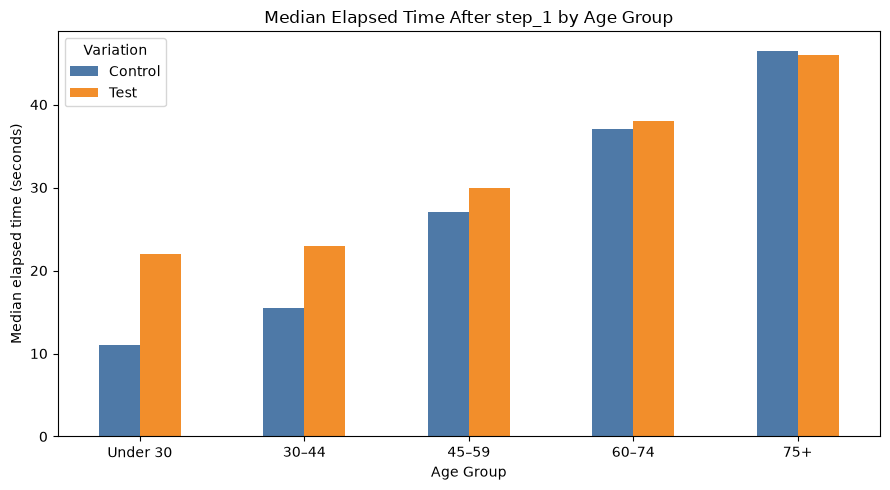

In [221]:
# Plot client-level median elapsed times by age group and variation

# Calculate the median client-level time for each age group and experiment group
age_plot_data = (
    client_age_time.groupby(["age_group", "Variation"], observed=True)[
        "median_time_seconds"
    ]
    .median()
    .unstack("Variation")
    .reindex(age_groups)
)

# Create a side-by-side bar chart using the same colours as Tableau
ax = age_plot_data[["Control", "Test"]].plot(
    kind="bar", figsize=(9, 5), color=["#4E79A7", "#F28E2B"]
)

# Add clear labels and a title
ax.set_xlabel("Age Group")
ax.set_ylabel("Median elapsed time (seconds)")
ax.set_title("Median Elapsed Time After step_1 by Age Group")
ax.legend(title="Variation")

# Keep age labels horizontal and tidy the layout
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Prepare the Tableau Dataset

We create a separate dataset by combining the time intervals with client information. This allows us to compare time efficiency between the Test and Control groups and explore differences across client demographics.

Intervals with zero or negative durations are excluded because they cannot represent a positive elapsed time. The original data remains unchanged.

In [222]:
# Prepare client-level timing data for Tableau

# Start with the cleaned experimental website data
df_tableau_time = df.copy()

# Convert timestamps and sort events within each visit
df_tableau_time["date_time"] = pd.to_datetime(df_tableau_time["date_time"])

df_tableau_time = df_tableau_time.sort_values(
    ["client_id", "visit_id", "date_time"]
).copy()

# Find the next event within each visit
grouped = df_tableau_time.groupby(["client_id", "visit_id"])

df_tableau_time["next_date_time"] = grouped["date_time"].shift(-1)

# Calculate elapsed time between consecutive events
df_tableau_time["time_seconds"] = (
    df_tableau_time["next_date_time"] - df_tableau_time["date_time"]
).dt.total_seconds()

# Keep valid positive intervals, excluding time after confirm
df_tableau_time = df_tableau_time.loc[
    df_tableau_time["next_date_time"].notna()
    & (df_tableau_time["time_seconds"] > 0)
    & (df_tableau_time["process_step"] != "confirm")
].copy()

# Calculate one median time per client and process step
df_tableau_time = df_tableau_time.groupby(
    ["client_id", "Variation", "process_step"], as_index=False
)["time_seconds"].median()

# Add client details without duplicating the Variation column
df_client_info = clients.drop(columns=["Variation"])

df_tableau_time = df_tableau_time.merge(
    df_client_info, on="client_id", how="left", validate="many_to_one"
)

# Check the dataset before exporting
print("Dataset shape:", df_tableau_time.shape)
print("\nRows by process step:")
print(df_tableau_time["process_step"].value_counts())
print("\nMissing experiment assignments:", df_tableau_time["Variation"].isna().sum())

Dataset shape: (164257, 14)

Rows by process step:
process_step
start     46122
step_1    42310
step_2    39558
step_3    36267
Name: count, dtype: int64

Missing experiment assignments: 0


#### Export the Tableau Dataset

Export the cleaned timing data, experiment group and client information to a CSV file. This file will be used to build the time-efficiency dashboard in Tableau.

In [ ]:
# Export the updated client-level dataset for Tableau

# Save to a new filename to preserve the original CSV
tableau_file = Path.cwd() / "df_tableau_time_client_level.csv"
df_tableau_time.to_csv(tableau_file, index=False)

# Confirm the file was saved correctly
print("File saved to:", tableau_file)
print("Rows:", len(df_tableau_time))
print("Columns:", len(df_tableau_time.columns))
print("Missing Test/Control assignments:", df_tableau_time["Variation"].isna().sum())

File saved to: c:\Ironhack Data Analysis - Sep2026\Ironhack_Projects\Unit_5\vanguard-ab-test-project2\df_tableau_time_client_level.csv
Rows: 164257
Columns: 14
Missing Test/Control assignments: 0


In [224]:
tableau_file = Path.cwd() / "df_tableau_time.csv"
df_tableau_time.to_csv(tableau_file, index=False)

print("File saved to:", tableau_file)
print("Rows:", len(df_tableau_time))
print("Columns:", len(df_tableau_time.columns))

File saved to: c:\Ironhack Data Analysis - Sep2026\Ironhack_Projects\Unit_5\vanguard-ab-test-project2\df_tableau_time.csv
Rows: 164257
Columns: 14


### 2.3 Error Rate

In [225]:
# Day 3 — Error Rate Analysis
print(df.shape)
print(df.columns.tolist())
display(df.head())

(317235, 6)
['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time', 'Variation']


,client_id,visitor_id,visit_id,process_step,date_time,Variation
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,Test
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,Test
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,Test
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,Test
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,Test


In [226]:
# Define the correct order of the process steps
step_map = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}

# Create a numerical column for each step
df["step_number"] = df["process_step"].map(step_map)

# Check the result
display(df[["process_step", "step_number"]].head(10))

,process_step,step_number
0,step_3,3
1,step_2,2
2,step_3,3
3,step_2,2
4,step_3,3
5,step_2,2
6,step_1,1
7,start,0
8,confirm,4
9,step_3,3


In [227]:
# Convert timestamps to datetime
df["date_time"] = pd.to_datetime(df["date_time"])

# Sort events chronologically within each visit
df = df.sort_values(["client_id", "visit_id", "date_time"], kind="stable").copy()

# Check the chronological order
display(
    df[["client_id", "visit_id", "date_time", "process_step", "step_number"]].head(10)
)

,client_id,visit_id,date_time,process_step,step_number
70440,555,637149525_38041617439_716659,2017-04-15 12:57:56,start,0
70439,555,637149525_38041617439_716659,2017-04-15 12:58:03,step_1,1
70438,555,637149525_38041617439_716659,2017-04-15 12:58:35,step_2,2
70437,555,637149525_38041617439_716659,2017-04-15 13:00:14,step_3,3
70436,555,637149525_38041617439_716659,2017-04-15 13:00:34,confirm,4
135231,647,40369564_40101682850_311847,2017-04-12 15:41:28,start,0
135230,647,40369564_40101682850_311847,2017-04-12 15:41:35,step_1,1
135229,647,40369564_40101682850_311847,2017-04-12 15:41:53,step_2,2
135228,647,40369564_40101682850_311847,2017-04-12 15:45:02,step_3,3
135225,647,40369564_40101682850_311847,2017-04-12 15:47:45,confirm,4


In [228]:
# Identify the previous step within each visit
df["previous_step"] = df.groupby(["client_id", "visit_id"])["step_number"].shift(1)

display(df[["visit_id", "process_step", "step_number", "previous_step"]].head(15))

,visit_id,process_step,step_number,previous_step
70440,637149525_38041617439_716659,start,0,NaN
70439,637149525_38041617439_716659,step_1,1,0.0
70438,637149525_38041617439_716659,step_2,2,1.0
70437,637149525_38041617439_716659,step_3,3,2.0
70436,637149525_38041617439_716659,confirm,4,3.0
135231,40369564_40101682850_311847,start,0,NaN
135230,40369564_40101682850_311847,step_1,1,0.0
135229,40369564_40101682850_311847,step_2,2,1.0
135228,40369564_40101682850_311847,step_3,3,2.0
135225,40369564_40101682850_311847,confirm,4,3.0


In [229]:
# Identify backward navigation
df["error"] = df["step_number"] < df["previous_step"]

# Display the results
display(
    df[["visit_id", "process_step", "step_number", "previous_step", "error"]].head(15)
)

,visit_id,process_step,step_number,previous_step,error
70440,637149525_38041617439_716659,start,0,NaN,False
70439,637149525_38041617439_716659,step_1,1,0.0,False
70438,637149525_38041617439_716659,step_2,2,1.0,False
70437,637149525_38041617439_716659,step_3,3,2.0,False
70436,637149525_38041617439_716659,confirm,4,3.0,False
135231,40369564_40101682850_311847,start,0,NaN,False
135230,40369564_40101682850_311847,step_1,1,0.0,False
135229,40369564_40101682850_311847,step_2,2,1.0,False
135228,40369564_40101682850_311847,step_3,3,2.0,False
135225,40369564_40101682850_311847,confirm,4,3.0,False


In [230]:
# Show examples of backward navigation
display(
    df[df["error"] == True][
        [
            "client_id",
            "visit_id",
            "process_step",
            "previous_step",
            "step_number",
            "Variation",
        ]
    ].head(10)
)

,client_id,visit_id,process_step,previous_step,step_number,Variation
129569,1028,557292053_87239438319_391157,step_1,3.0,1,Control
129566,1028,557292053_87239438319_391157,step_1,2.0,1,Control
31041,1197,71862471_21202285428_848395,step_2,3.0,2,Control
277652,1346,27144337_83739845380_214282,start,1.0,0,Test
277648,1346,27144337_83739845380_214282,start,3.0,0,Test
83827,1516,481123290_95510977345_707323,step_1,2.0,1,Test
83825,1516,481123290_95510977345_707323,start,2.0,0,Test
83820,1516,481123290_95510977345_707323,step_1,2.0,1,Test
235696,1643,633860590_96880450633_976109,start,1.0,0,Test
47915,1836,275887696_51740057136_798210,start,1.0,0,Test


In [231]:
# Exclude the first event of each visit
transitions = df[df["previous_step"].notna() & df["step_number"].notna()].copy()

# Calculate error rate for each group
error_summary = transitions.groupby("Variation").agg(
    total_transitions=("error", "count"),
    total_errors=("error", "sum"),
    error_rate=("error", "mean"),
)

# Convert error rate into percentage
error_summary["error_rate"] *= 100

# Display results
display(error_summary.round(2))

,total_transitions,total_errors,error_rate
Variation,,,
Control,108293,9581,8.85
Test,139495,16232,11.64


In [232]:
# How to understand the result
# - If Test has a lower error rate, the new interface shows fewer backward movements.
# - If Control has a lower error rate, the original interface shows fewer backward movements.
# - If they are almost equal, there may be little difference in navigation behavior.
#  backward navigation is a proxy for possible errors, not a confirmed technical error.

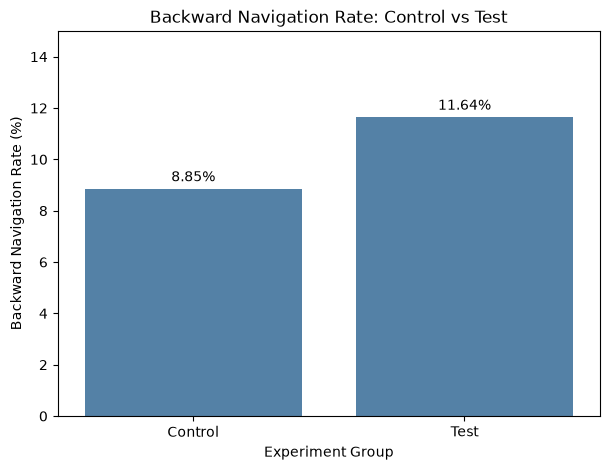

In [233]:
plt.figure(figsize=(7, 5))

sns.barplot(x=error_summary.index, y=error_summary["error_rate"], color="steelblue")

plt.title("Backward Navigation Rate: Control vs Test")
plt.xlabel("Experiment Group")
plt.ylabel("Backward Navigation Rate (%)")
plt.ylim(0, 15)

for i, value in enumerate(error_summary["error_rate"]):
    plt.text(i, value + 0.3, f"{value:.2f}%", ha="center")

plt.show()

#### KPI 3 — Error Rate Analysis

Objective: Evaluate whether Vanguard's redesigned website reduces navigation errors compared with the original design.

Method: Backward navigation was used as a proxy for potential errors. Each client's interactions were sorted chronologically within their website visit. A backward movement was recorded whenever the client returned from a later process step to an earlier step.

Results:

Control Group: 8.26% backward-navigation rate.

Test Group: 11.54% backward-navigation rate.

Difference: +3.28 percentage points in the Test group.

Interpretation:

The redesigned interface showed a higher backward-navigation rate than the original website. This suggests that the new design may introduce additional navigation friction.

However, backward navigation does not necessarily indicate a technical error, as clients may intentionally return to previous steps.

Conclusion: Based on this KPI, the original interface performed better. Further investigation is needed to determine whether the difference is statistically significant and which process steps contribute most to backward navigation.

In [234]:
url = "https://raw.githubusercontent.com/data-bootcamp-v4/lessons/main/5_6_eda_inf_stats_tableau/project/files_for_project/df_final_demo.txt"

demo = pd.read_csv(url)

display(demo.head())

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


In [235]:
# Add client age to website activity data
df_age = df.merge(
    demo[["client_id", "clnt_age"]], on="client_id", how="left", validate="many_to_one"
)

display(df_age[["client_id", "clnt_age", "process_step", "error"]].head())

,client_id,clnt_age,process_step,error
0,555,29.5,start,False
1,555,29.5,step_1,False
2,555,29.5,step_2,False
3,555,29.5,step_3,False
4,555,29.5,confirm,False


In [236]:
# Keep only valid transitions with known ages
valid = df_age[
    df_age["previous_step"].notna()
    & df_age["step_number"].notna()
    & df_age["clnt_age"].notna()
].copy()

# Calculate backward navigation rate per client
client_errors = (
    valid.groupby(["client_id", "Variation"])
    .agg(
        age=("clnt_age", "first"),
        total_transitions=("error", "count"),
        backward_moves=("error", "sum"),
        error_rate=("error", "mean"),
    )
    .reset_index()
)

# Convert to percentage
client_errors["error_rate"] *= 100

display(client_errors.head(10))

,client_id,Variation,age,total_transitions,backward_moves,error_rate
0,555,Test,29.5,4,0,0.000000
1,647,Test,57.5,4,0,0.000000
2,934,Test,51.0,3,0,0.000000
3,1028,Control,36.0,8,2,25.000000
4,1186,Control,22.0,2,0,0.000000
5,1195,Control,54.5,4,0,0.000000
6,1197,Control,28.5,6,1,16.666667
7,1336,Test,42.0,5,0,0.000000
8,1346,Test,46.0,9,2,22.222222
9,1516,Test,58.5,14,3,21.428571


In [237]:
rho, p_value = spearmanr(client_errors["age"], client_errors["error_rate"])

print("Spearman correlation:", round(rho, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Statistically significant association.")
else:
    print("Fail to reject H0: No statistically significant association detected.")

Spearman correlation: 0.0683
P-value: 3.289371878803227e-49
Reject H0: Statistically significant association.


Testing whether older clients tend to have more difficulty navigating the website than younger clients.
And latest results actually tell us something interesting!
1. What have we done so far?
We started with two questions.
Question 1: Does the new website have more backward navigation than the old website?
calculated:
Original website8.26%
Backward transitions


Redesigned website11.54%
Backward transitions



The new website has more backward navigation.
Question 2: Is client age associated with backward navigation?
That's what just tested using Spearman correlation.
2. What do latest results mean?

Spearman correlation (ρ)
0.0683


P-value
3.29 × 10⁻⁴⁹

Calculated from client-level data, combining Control and Test groups.
What does 0.0683 mean?
Correlation measures whether two variables tend to change together.
In your case:
- Variable 1: Client age
- Variable 2: Percentage of backward navigation
A positive correlation means that older clients tend to have higher backward-navigation rates.
But 0.0683 is extremely close to zero, meaning the relationship is very weak.
What does the p-value mean?
Your p-value is extremely small, well below the usual significance threshold of 0.05.
That means the data provides statistical evidence of an association, even though the association is weak.
So your conclusion is:
Age has a statistically significant but very weak positive association with backward-navigation rate.
This does not mean that older clients necessarily struggle with the website, or that age causes backward navigation.
3. Why did we do hypothesis testing?
A hypothesis test helps us decide whether the pattern in our data is convincing enough to reject a specific statistical assumption.
For your analysis:
	Hypothesis
H₀ — Null hypothesis	There is no monotonic association between age and backward-navigation rate.
H₁ — Alternative hypothesis	There is a monotonic association between age and backward-navigation rate.
Because your p-value is below 0.05, we reject H₀.
But this is where statistical significance and practical importance are different.
 sample contains many clients, which can make even a very small association statistically significant.


In [238]:
for group in ["Control", "Test"]:
    subset = client_errors[client_errors["Variation"] == group]

    rho, p = spearmanr(subset["age"], subset["error_rate"])

    print(group)
    print("Correlation:", round(rho, 4))
    print("P-value:", p)
    print()

Control
Correlation: 0.0334
P-value: 1.2319883695528085e-06

Test
Correlation: 0.0962
P-value: 2.571381952483131e-53



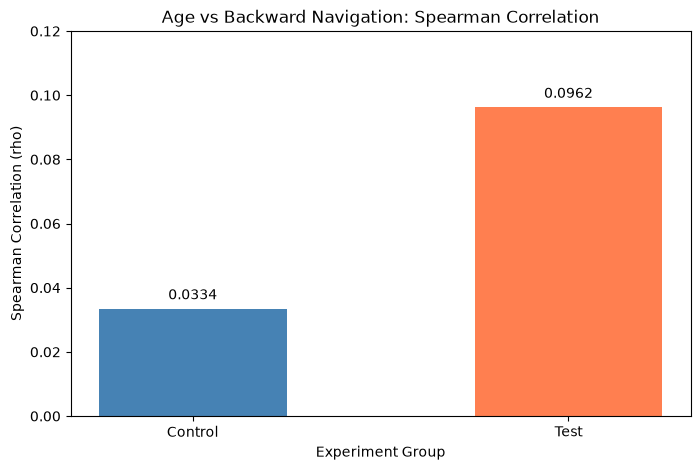

In [239]:
groups = ["Control", "Test"]
correlations = [0.0334, 0.0962]

plt.figure(figsize=(8, 5))

bars = plt.bar(groups, correlations, color=["steelblue", "coral"], width=0.5)

# Add numbers above the bars
for bar, value in zip(bars, correlations):
    plt.text(
        bar.get_x() + bar.get_width() / 2, value + 0.003, f"{value:.4f}", ha="center"
    )

plt.title("Age vs Backward Navigation: Spearman Correlation")
plt.xlabel("Experiment Group")
plt.ylabel("Spearman Correlation (rho)")
plt.ylim(0, 0.12)

plt.show()

- Control (0.0334): Almost no relationship between age and backward navigation.
- Test (0.0962): A very weak positive relationship.

In [240]:
client_errors["age_group"] = pd.cut(
    client_errors["age"],
    bins=[0, 30, 45, 60, 75, float("inf")],
    labels=["Under 30", "30–44", "45–59", "60–74", "75+"],
    right=False,
)

In [241]:
age_summary = (
    client_errors.groupby(["age_group", "Variation"], observed=True)
    .agg(
        backward_moves=("backward_moves", "sum"),
        total_transitions=("total_transitions", "sum"),
    )
    .reset_index()
)

age_summary["error_rate"] = (
    age_summary["backward_moves"] / age_summary["total_transitions"] * 100
)

display(age_summary.round(2))

,age_group,Variation,backward_moves,total_transitions,error_rate
0,Under 30,Control,1490,17451,8.54
1,Under 30,Test,1981,21629,9.16
2,30–44,Control,2173,27758,7.83
3,30–44,Test,3141,34257,9.17
4,45–59,Control,3035,34255,8.86
5,45–59,Test,5433,44346,12.25
6,60–74,Control,2529,25465,9.93
7,60–74,Test,4908,34522,14.22
8,75+,Control,349,3318,10.52
9,75+,Test,766,4697,16.31


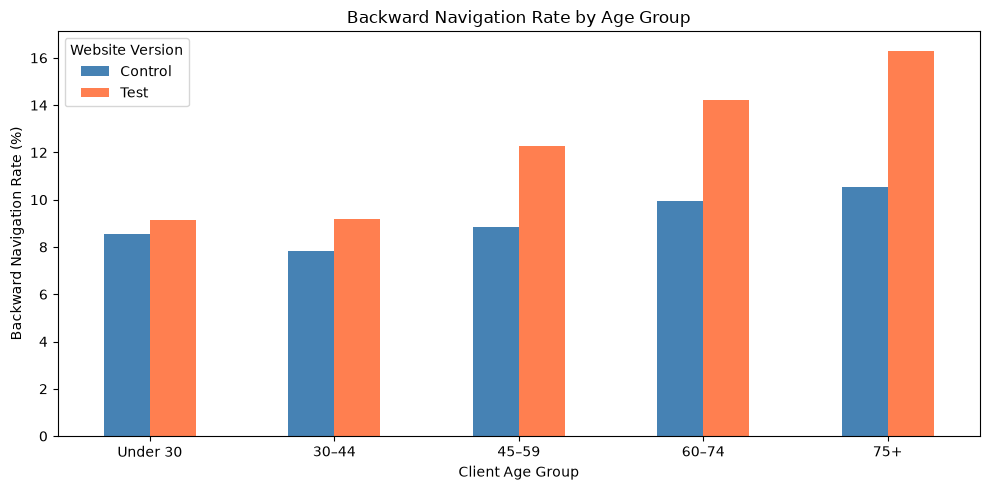

In [242]:
age_chart = age_summary.pivot(
    index="age_group", columns="Variation", values="error_rate"
)

age_chart = age_chart[["Control", "Test"]]

ax = age_chart.plot(kind="bar", figsize=(10, 5), color=["steelblue", "coral"])

plt.title("Backward Navigation Rate by Age Group")
plt.xlabel("Client Age Group")
plt.ylabel("Backward Navigation Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Website Version")
plt.tight_layout()
plt.show()

#### Backward Navigation by Age Group — Findings

The analysis examined backward-navigation rates across five age groups for both the Control and Test interfaces.

The redesigned interface demonstrated higher backward-navigation rates across all age groups. The difference was smallest among clients under 30 (+0.62 percentage points) and largest among clients aged 75 and above (+5.79 percentage points).

The observed gap increased with age, suggesting that older clients may experience greater navigation friction with the redesigned interface.

However, backward navigation is not necessarily a technical error, and these descriptive comparisons do not independently establish statistical significance.

**Recommendation:** Vanguard should investigate the usability of the redesigned interface among older clients, particularly those aged 60 and above, and identify which process steps contribute most to backward navigation.

Chart suggests that the gap between Control and Test increases with age. Now we'll test whether that pattern is statistically significant.
Step 1 — Understand the hypotheses
- H₀ (Null hypothesis): The relationship between age and backward navigation is the same for the Control and Test groups.
- H₁ (Alternative hypothesis): The relationship between age and backward navigation differs between the Control and Test groups.
 use binomial logistic regression with an interaction term.
The interaction term age × website version is the important part. It tells us whether the association between age and backward navigation changes depending on which website a client used.
Step 2 — Prepare the data
already have client_errors with these columns:
client_id, Variation, age, total_transitions, backward_moves, and error_rate.

In [243]:
# Copy our client-level dataset
model_data = client_errors.copy()

# Convert experiment group to numerical values
# Control = 0, Test = 1
model_data["test"] = (model_data["Variation"] == "Test").astype(int)

# Express age in decades, centered at age 50
model_data["age_10"] = (model_data["age"] - 50) / 10

# Create an interaction variable
model_data["age_test"] = model_data["age_10"] * model_data["test"]

display(model_data.head())

,client_id,Variation,age,total_transitions,backward_moves,error_rate,age_group,test,age_10,age_test
0,555,Test,29.5,4,0,0.0,Under 30,1,-2.05,-2.05
1,647,Test,57.5,4,0,0.0,45–59,1,0.75,0.75
2,934,Test,51.0,3,0,0.0,45–59,1,0.10,0.10
3,1028,Control,36.0,8,2,25.0,30–44,0,-1.40,-0.00
4,1186,Control,22.0,2,0,0.0,Under 30,0,-2.80,-0.00


In [244]:
# Independent variables
X = model_data[["age_10", "test", "age_test"]]

X = sm.add_constant(X)

# Outcome: backward moves vs non-backward moves
y = np.column_stack(
    [
        model_data["backward_moves"],
        model_data["total_transitions"] - model_data["backward_moves"],
    ]
)

# Binomial logistic regression
model = sm.GLM(y, X, family=sm.families.Binomial())

# Cluster standard errors by client
results = model.fit(cov_type="cluster", cov_kwds={"groups": model_data["client_id"]})

print(results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           ['y1', 'y2']   No. Observations:                46550
Model:                            GLM   Df Residuals:                    46546
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -38476.
Date:                Thu, 22 Oct 2026   Deviance:                       45603.
Time:                        13:39:57   Pearson chi2:                 4.17e+04
No. Iterations:                     6   Pseudo R-squ. (CS):            0.02584
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.3253      0.012   -192.203      0.0

In [245]:
interaction_coef = results.params["age_test"]
interaction_p = results.pvalues["age_test"]

print("Interaction coefficient:", round(interaction_coef, 4))

print("Interaction p-value:", interaction_p)

print("Interaction odds ratio:", round(np.exp(interaction_coef), 4))

if interaction_p < 0.05:
    print("Reject H0: Significant age × interface interaction.")
else:
    print("Fail to reject H0: No significant interaction detected.")

Interaction coefficient: 0.0783
Interaction p-value: 2.8412730142146414e-14
Interaction odds ratio: 1.0814
Reject H0: Significant age × interface interaction.


What does this tell us?
First finding: The Test group has more backward navigation in every age group.
Second finding: The difference between the old and new interfaces becomes progressively larger among older age groups.
Third finding: The largest difference appears among clients aged 75 and above.

#### Backward Navigation by Age Group — Findings

The analysis examined backward-navigation rates across five age groups for both the Control and Test interfaces.

The redesigned interface demonstrated higher backward-navigation rates across all age groups. The difference was smallest among clients under 30 (+0.62 percentage points) and largest among clients aged 75 and above (+5.79 percentage points).

The observed gap increased with age, suggesting that older clients may experience greater navigation friction with the redesigned interface.

However, backward navigation is not necessarily a technical error, and these descriptive comparisons do not independently establish statistical significance.

**Recommendation:** Vanguard should investigate the usability of the redesigned interface among older clients, particularly those aged 60 and above, and identify which process steps contribute most to backward navigation.

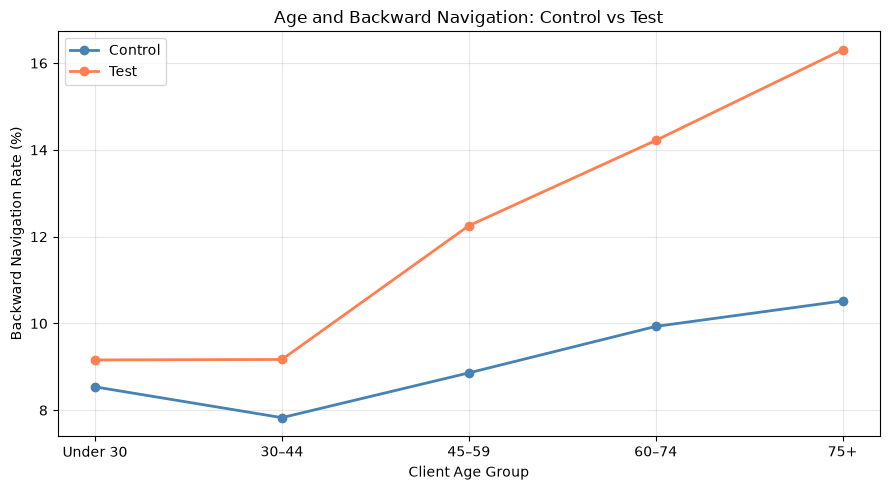

In [246]:
# Reshape your existing age-group results
age_chart = age_summary.pivot(
    index="age_group", columns="Variation", values="error_rate"
)

# Keep age groups in the correct order
age_order = ["Under 30", "30–44", "45–59", "60–74", "75+"]

age_chart = age_chart.reindex(age_order)

# Create line chart
plt.figure(figsize=(9, 5))

plt.plot(
    age_chart.index,
    age_chart["Control"],
    marker="o",
    linewidth=2,
    label="Control",
    color="steelblue",
)

plt.plot(
    age_chart.index,
    age_chart["Test"],
    marker="o",
    linewidth=2,
    label="Test",
    color="coral",
)

plt.title("Age and Backward Navigation: Control vs Test")
plt.xlabel("Client Age Group")
plt.ylabel("Backward Navigation Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This chart makes three things immediately visible:
- The Test group has higher backward-navigation rates in every age group.
- The difference becomes larger among older clients.
- The redesigned interface appears particularly problematic for the oldest clients, as measured by this navigation proxy.

#### Age × Interface Interaction — Visualization

The line chart illustrates how backward-navigation rates vary by client age and website version.

The Test group consistently shows higher backward-navigation rates than the Control group, with the difference increasing across older age groups.

A binomial logistic regression confirmed a statistically significant age-by-interface interaction (β = 0.0783, p < 0.001).

**Business implication:** Vanguard should investigate whether the redesigned interface creates additional navigation difficulties for older clients, particularly those aged 60 and above.

Backward navigation is used as a proxy for potential friction rather than a direct measure of technical errors.

In [247]:
print("df exists:", "df" in globals())
print("demo exists:", "demo" in globals())
print("df_age exists:", "df_age" in globals())
print("client_errors exists:", "client_errors" in globals())

df exists: True
demo exists: True
df_age exists: True
client_errors exists: True


In [248]:
print("df exists:", "df" in globals())
print("demo exists:", "demo" in globals())

df exists: True
demo exists: True


In [249]:
url = (
    "https://raw.githubusercontent.com/data-bootcamp-v4/lessons/"
    "main/5_6_eda_inf_stats_tableau/project/files_for_project/"
    "df_final_demo.txt"
)

demo = pd.read_csv(url)

print("Demographics loaded:", demo.shape)

Demographics loaded: (70609, 9)


In [250]:
# Convert timestamps to datetime
df["date_time"] = pd.to_datetime(df["date_time"])

# Define process step order
step_map = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}

# Sort events chronologically
df = df.sort_values(["client_id", "visit_id", "date_time"], kind="stable").copy()

# Convert steps to numbers
df["step_number"] = df["process_step"].map(step_map)

# Identify the previous step within each visit
df["previous_step"] = df.groupby(["client_id", "visit_id"])["step_number"].shift(1)

# Check columns
print(df.columns.tolist())

['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time', 'Variation', 'step_number', 'previous_step', 'error']


In [251]:
# Add demographics to website activity
tableau_data = df.merge(
    demo[["client_id", "clnt_age", "gendr"]],
    on="client_id",
    how="left",
    validate="many_to_one",
)

# Create age groups
tableau_data["age_group"] = pd.cut(
    tableau_data["clnt_age"],
    bins=[0, 30, 45, 60, 75, float("inf")],
    labels=["Under 30", "30–44", "45–59", "60–74", "75+"],
    right=False,
)

# Define valid transitions and backward movements
tableau_data["valid_transition"] = (
    tableau_data["previous_step"].notna() & tableau_data["step_number"].notna()
).astype(int)

tableau_data["backward_move"] = (
    (tableau_data["step_number"] < tableau_data["previous_step"])
    & (tableau_data["valid_transition"] == 1)
).astype(int)

# Export
tableau_data.to_csv("vanguard_tableau_data.csv", index=False)

print("Tableau dataset exported!")
print(tableau_data.shape)

Tableau dataset exported!
(317235, 14)


In [252]:
check = tableau_data.groupby("Variation").agg(
    backward_moves=("backward_move", "sum"),
    valid_transitions=("valid_transition", "sum"),
)

check["error_rate"] = check["backward_moves"] / check["valid_transitions"] * 100

display(check.round(2))

,backward_moves,valid_transitions,error_rate
Variation,,,
Control,9581,108293,8.85
Test,16232,139495,11.64


In [253]:
print(os.path.abspath("vanguard_tableau_data.csv"))

c:\Ironhack Data Analysis - Sep2026\Ironhack_Projects\Unit_5\vanguard-ab-test-project2\vanguard_tableau_data.csv
